In [1]:
import pandas as pd 
import numpy as np

import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import seaborn as sns
%matplotlib inline
import plotly.graph_objs as go
import plotly.figure_factory as ff
from plotly import tools
from plotly.offline import download_plotlyjs, init_notebook_mode, plot, iplot

import geopandas as gpd
from geopy.distance import geodesic
from shapely.geometry import Point

init_notebook_mode(connected=True)

import re
import random
import operator

import gc
from datetime import datetime 
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.cluster import KMeans

import sklearn.metrics as metrics

import category_encoders as ce

from IPython.display import HTML
import warnings

import nltk
from nltk.corpus import stopwords
import string

from sklearn.preprocessing import StandardScaler
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA

from sklearn.datasets import make_classification
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import SMOTE

from sklearn.preprocessing import KBinsDiscretizer

from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules
from mlxtend.preprocessing import TransactionEncoder

from sklearn.metrics.pairwise import cosine_similarity


pd.set_option('display.max_columns', 100)


RFC_METRIC = 'gini'  #metric used for RandomForrestClassifier
NUM_ESTIMATORS = 100 #number of estimators used for RandomForrestClassifier
NO_JOBS = 4 #number of parallel jobs used for RandomForrestClassifier


#TRAIN/VALIDATION/TEST SPLIT
#VALIDATION
VALID_SIZE = 0.20 # simple validation using train_test_split
TEST_SIZE = 0.20 # test size using_train_test_split

#CROSS-VALIDATION
NUMBER_KFOLDS = 5 #number of KFolds for cross-validation



RANDOM_STATE = 2000

MAX_ROUNDS = 1000 #lgb iterations
EARLY_STOP = 50 #lgb early stop 
OPT_ROUNDS = 1000  #To be adjusted based on best validation rounds
VERBOSE_EVAL = 50 #Print out metric result

IS_LOCAL = False

warnings.filterwarnings('default') # enable Python warnings in this file

~/anaconda3/envs/myenv1/lib/python3.11/site-packages/sentence_transformers/cross_encoder/CrossEncoder.py:11: TqdmExperimentalWarning:

Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)



In [ ]:
import os
from pathlib import Path

# Run from the project directory, the one containing fraudTrain_encoded.csv.
path = str(Path.cwd()) + os.sep
if not (Path(path) / "fraudTrain_encoded.csv").exists():
    print("fraudTrain_encoded.csv not found: start Jupyter in the project directory")
os.chdir(path)
print("working directory:", path)


#### Read CSV and Check

In [3]:
original_df = pd.read_csv(path+"fraudTrain.csv")
data_df = original_df.copy()

data_df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,NC,28654,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,WA,99160,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,ID,83252,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,MT,59632,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,VA,24433,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [4]:
print("Credit Card Fraud Detection data -  rows:",data_df.shape[0]," columns:", data_df.shape[1])

Credit Card Fraud Detection data -  rows: 1296675  columns: 23


In [5]:
data_df.iloc[648695:972802,:]

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
648695,648695,2019-10-03 13:01:14,3500165543009955,"fraud_Wintheiser, Dietrich and Schimmel",misc_pos,56.54,Ricky,Dunn,M,97689 Davis Point Apt. 967,Detroit,MI,48214,42.3669,-82.9938,673342,Health visitor,1983-09-02,02140d1acf1dcace6790f08295be41c9,1349269274,41.647366,-83.033624,0
648696,648696,2019-10-03 13:01:26,4070511711385545,fraud_Kub PLC,personal_care,23.57,Stephanie,Hopkins,F,44089 Carrie Crossing Suite 954,Falls City,TX,78113,28.9814,-98.0156,2435,"Engineer, mining",1967-04-09,70d6ad02f95a72915450084c1f8af86d,1349269286,28.925851,-97.272381,0
648697,648697,2019-10-03 13:04:18,4229733778084049,"fraud_Rodriguez, Yost and Jenkins",misc_net,1.01,Tyler,Mills,M,7838 Jason Squares,Elizabethtown,KY,42701,37.6848,-85.8784,48194,Surgeon,1990-05-03,ae9daa7141f57dca8b869466c820c04b,1349269458,37.895723,-86.252406,0
648698,648698,2019-10-03 13:04:41,630451534402,fraud_Botsford and Sons,home,89.49,Rachel,Daniels,F,561 Little Plain Apt. 738,Wetmore,MI,49895,46.3535,-86.6345,765,Immunologist,1972-06-12,90c403863cfe97cfe50b165d534c6335,1349269481,45.832974,-86.468676,0
648699,648699,2019-10-03 13:05:05,30344654314976,fraud_Berge-Hills,kids_pets,44.11,Christine,Johnson,F,8011 Chapman Tunnel Apt. 568,Blairsden-Graeagle,CA,96103,39.8127,-120.6405,1725,Chartered legal executive (England and Wales),1967-05-27,5bff7a00afaf1082b506b62689293e4b,1349269505,40.311833,-120.527706,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
972797,972797,2020-01-28 19:56:43,180017442990269,fraud_Kirlin and Sons,personal_care,22.38,Michelle,Anderson,F,28311 Dennis Trace,Albany,NY,12222,42.6853,-73.8253,151022,"Designer, textile",1939-06-01,d2bc5ab49e6a911194fad141f37700b8,1359403003,42.693395,-74.806303,0
972798,972798,2020-01-28 19:57:29,373043435942726,fraud_Daugherty LLC,kids_pets,55.60,Vincent,Richards,M,2064 Tyler Fork,Beasley,TX,77417,29.4790,-95.9681,2457,Trading standards officer,1981-03-04,f7df3d34ecccfe3d445cbff421cf4802,1359403049,28.963207,-95.546406,0
972799,972799,2020-01-28 19:57:55,6011399591920186,"fraud_Roberts, Ryan and Smith",personal_care,44.79,Maria,Roy,F,58665 Nicholas Ford Suite 348,Sheffield,MA,1257,42.1001,-73.3611,2121,Radio producer,1973-10-14,777a8e0d76036dd0b64cefea2cc1b309,1359403075,42.677274,-74.042998,0
972800,972800,2020-01-28 19:58:08,4379260813815979609,"fraud_Hauck, Dietrich and Funk",kids_pets,87.77,Thomas,Jenkins,M,93914 Gregory Via,Oakland,CA,94619,37.7878,-122.1884,381459,Barista,1974-01-03,2727455d769a156fad86c9d8b0d33d86,1359403088,37.344510,-122.485434,0


#### Remove unnecessary data, add time group, days type and change date time to hour

In [6]:
# remove some columns
df = original_df.copy()

drop_list = [0,2,3,6,7,9,12,18,19] # set columns id to drop the columns (inclu. index, cc_num, merchant, first name, last name, address, zip, trans_num, unix_time)
# drop merchant, names and address because is not relevant. drop trans_num because is unique. drop unix_time because we will have trans_time in hour
df.drop(columns=df.columns[drop_list], axis=1, inplace=True)

print(df.shape)

(1296675, 14)


In [7]:
# classify transaction time into time groups (bed time, office hour, evening)

df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'])

se_time_hour = df['trans_date_trans_time'].dt.hour # Extract the hour from 'trans_date_trans_time'

def classify_time(hour):
    if 0 <= hour < 8:
        return 0 # bed time
    elif 8 <= hour < 16:
        return 1 # office hour
    else:
        return 2 # evening

se_time_grp = se_time_hour.apply(classify_time)

df.insert(1, 'trans_time_grp', se_time_grp)

df

,trans_date_trans_time,trans_time_grp,category,amt,gender,city,state,lat,long,city_pop,job,dob,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,0,misc_net,4.97,F,Moravian Falls,NC,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,36.011293,-82.048315,0
1,2019-01-01 00:00:44,0,grocery_pos,107.23,F,Orient,WA,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,49.159047,-118.186462,0
2,2019-01-01 00:00:51,0,entertainment,220.11,M,Malad City,ID,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,43.150704,-112.154481,0
3,2019-01-01 00:01:16,0,gas_transport,45.00,M,Boulder,MT,46.2306,-112.1138,1939,Patent attorney,1967-01-12,47.034331,-112.561071,0
4,2019-01-01 00:03:06,0,misc_pos,41.96,M,Doe Hill,VA,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,38.674999,-78.632459,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1296670,2020-06-21 12:12:08,1,entertainment,15.56,M,Hatch,UT,37.7175,-112.4777,258,Geoscientist,1961-11-24,36.841266,-111.690765,0
1296671,2020-06-21 12:12:19,1,food_dining,51.70,M,Tuscarora,MD,39.2667,-77.5101,100,"Production assistant, television",1979-12-11,38.906881,-78.246528,0
1296672,2020-06-21 12:12:32,1,food_dining,105.93,M,High Rolls Mountain Park,NM,32.9396,-105.8189,899,Naval architect,1967-08-30,33.619513,-105.130529,0
1296673,2020-06-21 12:13:36,1,food_dining,74.90,M,Manderson,SD,43.3526,-102.5411,1126,Volunteer coordinator,1980-08-18,42.788940,-103.241160,0


In [8]:
# change trans_date_trans_time into format of hour
df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'])
time_difference = df['trans_date_trans_time'] - df['trans_date_trans_time'].iloc[0]

se_sec = pd.Series(time_difference.dt.total_seconds())

se_hour = se_sec.apply(lambda x: np.floor(x / 3600)) # applied lambda function for np flooring for division of 3600 to hours 
se_day = se_hour.apply(lambda x: np.floor(x / 24)) # applied lambda function for np flooring for division of 24 to days

df['trans_date_trans_time'] = se_hour # replace transaction date and time to the prefered unit (second or hour or day)

df.rename(columns = {'trans_date_trans_time':'trans_time'}, inplace = True) # rename the 'trans_date_trans_time' column

print("df before encoding:")
print(df.shape)
df

df before encoding:
(1296675, 15)


,trans_time,trans_time_grp,category,amt,gender,city,state,lat,long,city_pop,job,dob,merch_lat,merch_long,is_fraud
0,0.0,0,misc_net,4.97,F,Moravian Falls,NC,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,36.011293,-82.048315,0
1,0.0,0,grocery_pos,107.23,F,Orient,WA,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,49.159047,-118.186462,0
2,0.0,0,entertainment,220.11,M,Malad City,ID,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,43.150704,-112.154481,0
3,0.0,0,gas_transport,45.00,M,Boulder,MT,46.2306,-112.1138,1939,Patent attorney,1967-01-12,47.034331,-112.561071,0
4,0.0,0,misc_pos,41.96,M,Doe Hill,VA,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,38.674999,-78.632459,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1296670,12900.0,1,entertainment,15.56,M,Hatch,UT,37.7175,-112.4777,258,Geoscientist,1961-11-24,36.841266,-111.690765,0
1296671,12900.0,1,food_dining,51.70,M,Tuscarora,MD,39.2667,-77.5101,100,"Production assistant, television",1979-12-11,38.906881,-78.246528,0
1296672,12900.0,1,food_dining,105.93,M,High Rolls Mountain Park,NM,32.9396,-105.8189,899,Naval architect,1967-08-30,33.619513,-105.130529,0
1296673,12900.0,1,food_dining,74.90,M,Manderson,SD,43.3526,-102.5411,1126,Volunteer coordinator,1980-08-18,42.788940,-103.241160,0


#### Encoding data

In [ ]:
# Encoding 'category'

warnings.filterwarnings('ignore') # disable Python warning for this cell

df_enc = df.copy() # create a new DataFrame called df_enc

print("\nEncoding Category:")
cat_dict = dict(df['category'].value_counts())
print(df['category'].value_counts())
le = LabelEncoder()
le.fit(df['category'])
print("\nCategory size:",len(list(le.classes_)))

cat_table = pd.read_excel('encoding_table/Categories_encoding_V04.xlsx')
display(HTML(cat_table.to_html(index=True,header=True)))

category_list = ["home", "kids_pets", "entertainment", "food_dining", "health_fitness", "personal_care", "gas_transport", "travel", 
                 "grocery_net", "grocery_pos", "misc_net", "misc_pos", "shopping_net", "shopping_pos"]

category_code = {'home':'01110011',
 'kids_pets':'01110011',
 'entertainment':'00201000',
 'food_dining':'01001000',
 'health_fitness':'01010001',
 'personal_care':'01010001', # V25: was '001010001' (9 digits), which shifted every field by one
 'gas_transport':'01200020',
 'travel':'00301000',
 'grocery_net':'11000000',
 'grocery_pos':'01300030',
 'misc_net':'10300100',
 'misc_pos':'00100100',
 'shopping_net':'10300100',
 'shopping_pos' :'00200100'
}


assert all(len(v) == 8 and v.isdigit() for v in category_code.values()), "every category code must have 8 digits"

mapped_cat = df_enc['category'].map(category_code)

for i in range(0, 3):
    cat_enc = mapped_cat.apply(lambda x: str(x)[i]) # obtain the digits of the item
    cat_enc = [int(x) for x in cat_enc] # convert the series into integer
    df_enc.insert(3+i, f'category_{i+1}', cat_enc) # add the column

for i in range(0, 3):
    j = i+3
    alp_list = ['a','b','c','d','e']
    alp = alp_list[i]
    cat_enc = mapped_cat.apply(lambda x: str(x)[j]) # obtain the digits of the item
    cat_enc = [int(x) for x in cat_enc] # convert the series into integer
    df_enc.insert(6+i, f'category_4{alp}', cat_enc) # add the column

for i in range(6,8):
    j = i-5
    cat_enc = mapped_cat.apply(lambda x: str(x)[i]) # obtain the digits of the item
    cat_enc = [int(x) for x in cat_enc] # convert the series into integer
    df_enc.insert(3+i, f'category_interaction_{j}', cat_enc) # add the column
    

df_enc = df_enc.drop('category', axis=1) # drop the original 'category' column

df_cat = pd.DataFrame({'Encoded value': [_id for cat, _id in category_code.items()], 
                       'Category': [cat for cat, _id in category_code.items()]}) # create df for showing encoded values
display(HTML(df_cat.transpose().to_html(index=True,header=True))) # show encoded value of 'category'


display(HTML(df_enc.head().to_html(index=True,header=True)))

In [10]:
# Encoding 'gender'
print("\nEncoding Gender:")
gender_dict = dict(df['gender'].value_counts())
print(df['gender'].value_counts())
le = LabelEncoder()
le.fit(df['gender'])
print("\nGender size:",len(list(le.classes_)))

new_gen = le.transform(df['gender']) # transform gender to encoded number
gen_arr = np.arange(0,len(list(le.classes_)))
df_gen = pd.DataFrame({'Gender': list(le.classes_)})
df_gen['Count'] = None # pre-define a column for the DataFrame

for k in df_gen['Gender']: # obtain counts from the dictionary, then put it into the df of gender
    v = gender_dict.get(k)
    df_gen.loc[df_gen['Gender'] == k, 'Count'] = v

display(HTML(df_gen.transpose().to_html(index=True,header=True)))

df_enc['gender'] = new_gen

display(HTML(df_enc.head().to_html(index=True,header=True)))


Encoding Gender:
gender
F    709863
M    586812
Name: count, dtype: int64

Gender size: 2


,0,1
Gender,F,M
Count,709863,586812


,trans_time,trans_time_grp,category_1,category_2,category_3,category_4a,category_4b,category_4c,category_interaction_1,category_interaction_2,amt,gender,city,state,lat,long,city_pop,job,dob,merch_lat,merch_long,is_fraud
0,0.0,0,1,0,3,0,0,1,0,0,4.97,0,Moravian Falls,NC,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,36.011293,-82.048315,0
1,0.0,0,0,1,3,0,0,0,3,0,107.23,0,Orient,WA,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,49.159047,-118.186462,0
2,0.0,0,0,0,2,0,1,0,0,0,220.11,1,Malad City,ID,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,43.150704,-112.154481,0
3,0.0,0,0,1,2,0,0,0,2,0,45.00,1,Boulder,MT,46.2306,-112.1138,1939,Patent attorney,1967-01-12,47.034331,-112.561071,0
4,0.0,0,0,0,1,0,0,1,0,0,41.96,1,Doe Hill,VA,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,38.674999,-78.632459,0


In [11]:
# Encoding city (get state, county and city names)

def find_city_county_match(df_ref, df_actual):# check if any city and state pairs in CCF dataset aren't found in the ref
    match_dict = {}
    not_match_dict = {}
    
    for r in range(df_actual.shape[0]):
        city = df_actual.iloc[r]['city']
        state = df_actual.iloc[r]['state'] 
        
        try:
            filter_df = df_ref[(df_ref['state']==state)&(df_ref['primary_city']==city)]
            found_county = filter_df['county'].values[0]
            match_dict[r] = [state, city, found_county]
        except Exception as e:
            # print(e)
            not_match_dict[r] = [state, city]
    
    print(f"No. of matched CCF dataset cities: {len(match_dict)}, No. of unmatched CCF dataset cities: {len(not_match_dict)}")
    
    return match_dict

# get raw city and county data, filter and find unmatched CCF dataset pairs
df_city_county_original = pd.read_csv("encoding_table/ref_data/original/zip_code_database.csv")

city_county_data = df_city_county_original[['state', 'county', 'primary_city']] # select only relevant columns

df_city_county = pd.DataFrame(city_county_data)
df_city_county['county'] = df_city_county['county'].str.replace(r'\s+(County|Municipio)$', '', regex=True) # remove suffix
df_city_county = df_city_county.sort_values(by=['state', 'county', 'primary_city'])
df_city_county = df_city_county.reset_index(drop=True)

df_city_state = df_enc[['city', 'state']]
df_city_state = df_city_state.drop_duplicates(subset=['city', 'state']) # get only unique pairs
df_city_state = df_city_state.reset_index(drop=True)

print("Without manual data:")
city_county_match = find_city_county_match(df_city_county, df_city_state)

# manually add 5 remaining cities into country
manual_city_county = [ # State, County, Undefined City
    ['NY', 'New York', 'New York City'],
    ['CA', 'Plumas', 'Blairsden-Graeagle'],
    ['NM', 'Bernalillo', 'Kirtland Afb'],
    ['CA', 'Riverside', 'Sun City'],
    ['NY', 'Delaware', 'De Lancey']]

tmp = pd.DataFrame(manual_city_county, columns=['state', 'county', 'primary_city'])

df_city_county = pd.concat([df_city_county, tmp], axis=0, ignore_index=True) # add the 5 manually defined rows into ref data

print("With manual data:")
city_county_match = find_city_county_match(df_city_county, df_city_state)

# create sorted CCF city & state pairs with found county
df_state_city_county = pd.DataFrame.from_dict(city_county_match, orient='index', columns=['State', 'City', 'County'])
df_state_city_county = df_state_city_county.sort_values(by=['State', 'County', 'City'])
df_state_city_county = df_state_city_county.reset_index(drop=True)

df_state_city_county.to_csv("encoding_table/ref_data/city_county.csv", index=False)

df_state_city_county

Without manual data:
No. of matched CCF dataset cities: 923, No. of unmatched CCF dataset cities: 5
With manual data:
No. of matched CCF dataset cities: 928, No. of unmatched CCF dataset cities: 0


,State,City,County
0,AK,Wales,Nome Census Area
1,AK,Kaktovik,North Slope Borough
2,AK,Huslia,Yukon-Koyukuk Census Area
3,AL,Jones,Autauga
4,AL,Bay Minette,Baldwin
...,...,...,...
923,WY,Freedom,Lincoln
924,WY,Manville,Niobrara
925,WY,Yellowstone National Park,Park
926,WY,Rock Springs,Sweetwater


In [ ]:
# city and socio-economic status (income)

ref_city_table_original = pd.read_csv("encoding_table/ref_data/original/Unemployment_Income_2023.csv") # raw data of cities and income

# V25: drop the US and state totals (FIPS xx000). After ' County' is stripped below they collide
# with same-named counties (Arkansas, Hawaii, New York, Utah, ...), and they were counted in the quartiles.
ref_city_table = ref_city_table_original[(ref_city_table_original['Attribute']=='Median_Household_Income_2022')
                                        & (ref_city_table_original['FIPS_Code'] % 1000 != 0)]
ref_city_table = ref_city_table[['State', 'Area_Name', 'Attribute', 'Value']]
ref_city_table['Area_Name'] = ref_city_table['Area_Name'].str.replace(r'\s+(County).*$', '', regex=True)\
                                                         .str.replace(r',.*$', '', regex=True)

ref_city_county_pairs = set(zip(ref_city_table['State'], ref_city_table['Area_Name'])) # Area_Name is County
actual_city_county_pairs = zip(df_state_city_county['State'], df_state_city_county['County'])

def find_county_actual_ref_match(actual_pairs, ref_pairs):
    success_matches = {}
    failed_matches = {}
    
    for pair in actual_city_county_pairs:
        if pair in ref_city_county_pairs:
            success_matches[pair] = True
        else:
            failed_matches[pair] = False

    print(f"No. of success matches: {len(success_matches)}, No. of failed matches: {len(failed_matches)}")
    # print(failed_matches)
    if failed_matches: # not None
        print("Failed matches:\n", "\n".join(f"{k}: {v}" for k, v in failed_matches.items()))
    
print("Without manual added data:")
find_county_actual_ref_match(actual_city_county_pairs, ref_city_county_pairs)

manual_county_income = [ # State, Area_Name, Attribute, Value
    ['CT', 'Hartford', 'Median_Household_Income_2022', 80069], # https://data.census.gov/profile?g=050XX00US09003
    ['CT', 'Litchfield', 'Median_Household_Income_2022', 84978], # https://data.census.gov/profile/Litchfield_County,_Connecticut?g=050XX00US09005
    ['CT', 'Middlesex', 'Median_Household_Income_2022', 94887], # https://data.census.gov/profile/Middlesex_County,_Connecticut?g=050XX00US09007
    ['CT', 'New London', 'Median_Household_Income_2022', 78828], # https://data.census.gov/profile/New_London_County,_Connecticut?g=050XX00US09011
    ['MO', 'St Louis', 'Median_Household_Income_2022', 81441], # https://data.census.gov/profile/St._Louis_County,_Missouri?g=050XX00US29189
    ['VA', 'Alexandria City', 'Median_Household_Income_2022', 110294], # https://data.census.gov/profile/Alexandria_city,_Virginia?g=050XX00US51510
    ['VA', 'Hampton City', 'Median_Household_Income_2022', 70238], # https://data.census.gov/profile/Hampton_city,_Virginia?g=160XX00US5135000
    ['VA', 'Norfolk City', 'Median_Household_Income_2022', 62382]] # https://data.census.gov/profile/Norfolk_city,_Virginia?g=160XX00US5157000

tmp = pd.DataFrame(manual_county_income, columns=['State', 'Area_Name', 'Attribute', 'Value'])

ref_city_table = pd.concat([ref_city_table, tmp], axis=0, ignore_index=True) # add the 8 manually defined rows into ref data

ref_city_county_pairs = set(zip(ref_city_table['State'], ref_city_table['Area_Name'])) # Area_Name is County
actual_city_county_pairs = zip(df_state_city_county['State'], df_state_city_county['County'])

print("\nWith manual added data:")
find_county_actual_ref_match(actual_city_county_pairs, ref_city_county_pairs)

assert not ref_city_table.duplicated(['State', 'Area_Name']).any(), "one income row per county"
median_income = ref_city_table['Value']
q1, q2, q3 = np.percentile(median_income, 25), np.percentile(median_income, 50), np.percentile(median_income, 75) # get quartiles
ref_city_table['Median_income_quartile'] = pd.qcut(median_income, q=4, labels=['0', '1', '2', '3'])
print(q1, q2, q3)

ref_city_table.to_csv("encoding_table/ref_data/city_income.csv", index=False)

# display(HTML(ref_city_table.head().to_html(index=True,header=True)))
ref_city_table

In [13]:
# city and inequality (gini index)

ref_city_table_original = pd.read_csv("encoding_table/ref_data/original/ACSDT5Y2020.B19083-Data.csv") # raw data of cities and gini index
ref_city_table = ref_city_table_original.iloc[1:,:] # remove first unnecessary row
ref_city_table = ref_city_table.reset_index(drop=True)
ref_city_table = ref_city_table[['NAME','B19083_001E']]
ref_city_table.columns = ['Area', 'Gini_index']

df_state_id = pd.read_csv("encoding_table/ref_data/original/uscities.csv")
df_state_id = df_state_id[['state_name', 'state_id']]
df_state_id = df_state_id.drop_duplicates(subset=['state_name', 'state_id']) # get only unique pairs
df_state_id = df_state_id.sort_values(by='state_id')
df_state_id = df_state_id.reset_index(drop=True)

print("Used Simplemaps state name and id:")
display(HTML(df_state_id.head().to_html(index=True,header=True)))

ref_city_table['County'] = ref_city_table['Area'].str.replace(r'\s+(County|Municipio).*$', '', regex=True)\
                                                         .str.replace(r',.*$', '', regex=True)
ref_city_table['State_full_name'] = ref_city_table['Area'].str.split(',').str[1].str.strip()

state_map = df_state_id.set_index('state_name')['state_id']
ref_city_table['State'] = ref_city_table['State_full_name'].map(state_map)

ref_city_table = ref_city_table[['State', 'State_full_name', 'County', 'Gini_index']]

ref_city_county_pairs = set(zip(ref_city_table['State'], ref_city_table['County']))
actual_city_county_pairs = zip(df_state_city_county['State'], df_state_city_county['County'])
    
print("Without manual added data:")
find_county_actual_ref_match(actual_city_county_pairs, ref_city_county_pairs)

manual_county_gini = [ # State, State_full_name, County, Gini_index
    ['MO', 'Missouri', 'St Louis', 0.455 ], # https://datausa.io/profile/geo/st-louis-county-mo?redirect=true
    ['VA', 'Virginia', 'Alexandria City', 0.475], # https://datausa.io/profile/geo/alexandria-va#:~:text=In%202022%2C%20the%20income%20inequality,the%20national%20average%20of%200.478.
    ['VA', 'Virginia', 'Hampton City', 0.475], # https://datausa.io/profile/geo/hampton-va/#:~:text=In%202022%2C%20the%20income%20inequality,the%20national%20average%20of%200.478.
    ['VA', 'Virginia', 'Norfolk City', 0.475]] #

tmp = pd.DataFrame(manual_county_gini, columns=['State', 'State_full_name', 'County', 'Gini_index'])

ref_city_table = pd.concat([ref_city_table, tmp], axis=0, ignore_index=True) # add the 4 manually defined rows into ref data

ref_city_county_pairs = set(zip(ref_city_table['State'], ref_city_table['County']))
actual_city_county_pairs = zip(df_state_city_county['State'], df_state_city_county['County'])

print("\nWith manual added data:")
find_county_actual_ref_match(actual_city_county_pairs, ref_city_county_pairs)

ref_city_table['Gini_index'] = pd.to_numeric(ref_city_table['Gini_index'])
gini_index = ref_city_table['Gini_index']
q1, q2 = np.percentile(gini_index, 20), np.percentile(gini_index, 40) # get quintiles
q3, q4 = np.percentile(gini_index, 60), np.percentile(gini_index, 80) # get quintiles
ref_city_table['Gini_index_quintiles'] = pd.qcut(gini_index, q=5, labels=['0', '1', '2', '3', '4'])
# print(q1, q2, q3, q4)

ref_city_table.to_csv("encoding_table/ref_data/city_gini_index.csv", index=False)

# display(HTML(ref_city_table.head().to_html(index=True,header=True)))
ref_city_table

Used Simplemaps state name and id:


,state_name,state_id
0,Alaska,AK
1,Alabama,AL
2,Arkansas,AR
3,Arizona,AZ
4,California,CA


Without manual added data:
No. of success matches: 733, No. of failed matches: 4
Failed matches:
 ('MO', 'St Louis'): False
('VA', 'Alexandria City'): False
('VA', 'Hampton City'): False
('VA', 'Norfolk City'): False

With manual added data:
No. of success matches: 737, No. of failed matches: 0


,State,State_full_name,County,Gini_index,Gini_index_quintiles
0,AL,Alabama,Autauga,0.4552,3
1,AL,Alabama,Baldwin,0.4566,3
2,AL,Alabama,Barbour,0.5047,4
3,AL,Alabama,Bibb,0.4500,2
4,AL,Alabama,Blount,0.4685,3
...,...,...,...,...,...
3220,PR,Puerto Rico,Yauco,0.5080,4
3221,MO,Missouri,St Louis,0.4550,3
3222,VA,Virginia,Alexandria City,0.4750,3
3223,VA,Virginia,Hampton City,0.4750,3


In [14]:
# city and city type (urban influence)

ref_city_table_original = pd.read_csv("encoding_table/ref_data/original/UrbanInfluencecodes2024.csv") # raw data of cities and city type

ref_city_table = ref_city_table_original[ref_city_table_original['Attribute']=='UIC_2024']
ref_city_table = ref_city_table[['State', 'County_Name', 'Attribute', 'Value']]
ref_city_table['County_Name'] = ref_city_table['County_Name'].str.replace(r'\s+(County).*$', '', regex=True)\
                                                         .str.replace(r',.*$', '', regex=True)

ref_city_county_pairs = set(zip(ref_city_table['State'], ref_city_table['County_Name']))
actual_city_county_pairs = zip(df_state_city_county['State'], df_state_city_county['County'])
    
print("Without manual added data:")
find_county_actual_ref_match(actual_city_county_pairs, ref_city_county_pairs)

manual_county_urban = [ # State, County_Name, Attribute, Value
    ['CT', 'Hartford', 'UIC_2024', 1], # https://nstarr.arg.org/wp-content/uploads/2022/10/Connecticut_Final.pdf?
    ['CT', 'Litchfield', 'UIC_2024', 2],
    ['CT', 'Middlesex', 'UIC_2024', 1],
    ['CT', 'New London', 'UIC_2024', 4],
    ['IL', 'LaSalle', 'UIC_2024', 2], # https://www.ers.usda.gov/data-products/rural-urban-continuum-codes
    ['MO', 'St Louis', 'UIC_2024', 1], # https://mcdc.missouri.edu/help/ten-things/urban-rural.html
    ['VA', 'Alexandria City', 'UIC_2024', 1], # https://media.alexandriava.gov/docs-archives/housing/info/housing-master-plan-final.pdf
    ['VA', 'Hampton City', 'UIC_2024', 1], # https://vtrans.virginia.gov/resources/VMTP2025-Needs-Assessment/Regional-Network-Profiles/Hampton%20Roads%20Regional%20Needs%20Final.pdf
    ['VA', 'Norfolk City', 'UIC_2024', 1]]

tmp = pd.DataFrame(manual_county_urban, columns=['State', 'County_Name', 'Attribute', 'Value'])

ref_city_table = pd.concat([ref_city_table, tmp], axis=0, ignore_index=True) # add the 9 manually defined rows into ref data

ref_city_county_pairs = set(zip(ref_city_table['State'], ref_city_table['County_Name']))
actual_city_county_pairs = zip(df_state_city_county['State'], df_state_city_county['County'])

print("\nWith manual added data:")
find_county_actual_ref_match(actual_city_county_pairs, ref_city_county_pairs)

ref_city_table['Value'] = ref_city_table['Value'].astype(str)
county_code_type = {'1':'2', '2':'1', '3':'1', '4':'2', '5':'1', '6':'0', '7':'1', '8':'0', '9':'0'} # convert RUCC to rural/suburban/urban
ref_city_table['Encoded_urban_type'] = ref_city_table['Value'].map(county_code_type)
ref_city_table['Encoded_urban_type'] = pd.to_numeric(ref_city_table['Encoded_urban_type'])

ref_city_table.to_csv("encoding_table/ref_data/city_city_type.csv", index=False)

# display(HTML(ref_city_table.head().to_html(index=True,header=True)))
ref_city_table

Without manual added data:
No. of success matches: 728, No. of failed matches: 9
Failed matches:
 ('CT', 'Hartford'): False
('CT', 'Litchfield'): False
('CT', 'Middlesex'): False
('CT', 'New London'): False
('IL', 'LaSalle'): False
('MO', 'St Louis'): False
('VA', 'Alexandria City'): False
('VA', 'Hampton City'): False
('VA', 'Norfolk City'): False

With manual added data:
No. of success matches: 737, No. of failed matches: 0


,State,County_Name,Attribute,Value,Encoded_urban_type
0,AL,Autauga,UIC_2024,4,2
1,AL,Baldwin,UIC_2024,4,2
2,AL,Barbour,UIC_2024,5,1
3,AL,Bibb,UIC_2024,1,2
4,AL,Blount,UIC_2024,1,2
...,...,...,...,...,...
3237,IL,LaSalle,UIC_2024,2,1
3238,MO,St Louis,UIC_2024,1,2
3239,VA,Alexandria City,UIC_2024,1,2
3240,VA,Hampton City,UIC_2024,1,2


In [15]:
# city and digital connectivity A (fixed broadband coverage)

ref_city_table_original = pd.read_csv("encoding_table/ref_data/original/bdc_us_fixed_broadband_summary_by_geography_D22_04nov2024.csv") # raw data of cities fixed broadband

ref_city_table = ref_city_table_original[(ref_city_table_original['area_data_type']=='Total') \
                                        & (ref_city_table_original['geography_type']=='County')
                                        & (ref_city_table_original['technology']=='Any Technology')]
ref_city_table = ref_city_table[['geography_desc','geography_desc_full', 'biz_res', \
                                 'speed_100_20', 'speed_250_25', 'speed_1000_100']] # https://docs.fcc.gov/public/attachments/DOC-401205A1.pdf
broadband_state = ref_city_table['geography_desc_full'].str.split(',').str[1].str.strip()
ref_city_table.insert(1, 'state', broadband_state)
broadband_county = ref_city_table['geography_desc'].str.replace(r'\s+(County|Municipio).*$', '', regex=True)
ref_city_table.insert(1, 'county', broadband_county)
ref_city_table = ref_city_table.drop(['geography_desc', 'geography_desc_full'], axis=1)
# ref_city_table = ref_city_table.drop_duplicates(subset=['county', 'state', 'biz_res'])
ref_city_table = ref_city_table.reset_index(drop=True)
ref_city_table = ref_city_table.groupby(['county', 'state'], as_index=False).mean(numeric_only=True)

ref_city_county_pairs = set(zip(ref_city_table['state'], ref_city_table['county']))
actual_city_county_pairs = zip(df_state_city_county['State'], df_state_city_county['County'])

print("Without manual added data:")
find_county_actual_ref_match(actual_city_county_pairs, ref_city_county_pairs)

manual_county_fixbroadband = [ # county, state, speed_100, speed_250, speed_1000
    ['St Louis', 'MO', 1.0, 0.975, 0.949], # https://broadbandnow.com/Missouri/Saint-Louis
    ['Alexandria City', 'VA', 1.0, 0.696, 0.096], # https://broadbandnow.com/Virginia/Alexandria
    ['Hampton City', 'VA', 1.0, 0.713, 0.653], # https://broadbandnow.com/Virginia/Hampton
    ['Norfolk City', 'VA', 1.0, 0.619, 0.341]] # https://broadbandnow.com/Virginia/Norfolk

tmp = pd.DataFrame(manual_county_fixbroadband, columns=['county', 'state', 'speed_100_20', 'speed_250_25', 'speed_1000_100'])

ref_city_table = pd.concat([ref_city_table, tmp], axis=0, ignore_index=True) # add the 4 manually defined rows into ref data

ref_city_county_pairs = set(zip(ref_city_table['state'], ref_city_table['county']))
actual_city_county_pairs = zip(df_state_city_county['State'], df_state_city_county['County'])

print("\nWith manual added data:")
find_county_actual_ref_match(actual_city_county_pairs, ref_city_county_pairs)

speed_list = ['speed_100_20', 'speed_250_25', 'speed_1000_100']
for s in speed_list:
    ref_city_table[s] = pd.to_numeric(ref_city_table[s])
ref_city_table['fast_internet_avg_coverage'] = ref_city_table[speed_list].mean(axis=1)

fast_speed_coverage = ref_city_table['fast_internet_avg_coverage']
q1, q2 = np.percentile(fast_speed_coverage, 20), np.percentile(fast_speed_coverage, 40) # get quintiles
q3, q4 = np.percentile(fast_speed_coverage, 60), np.percentile(fast_speed_coverage, 80) # get quintiles
ref_city_table['fast_internet_coverage_quintiles'] = pd.qcut(fast_speed_coverage, q=5, labels=['0', '1', '2', '3', '4'])
# print(q1, q2, q3, q4)

ref_city_table.to_csv("encoding_table/ref_data/city_fixed_broadband.csv", index=False)

# display(HTML(ref_city_table.head().to_html(index=True,header=True)))
ref_city_table

Without manual added data:
No. of success matches: 733, No. of failed matches: 4
Failed matches:
 ('MO', 'St Louis'): False
('VA', 'Alexandria City'): False
('VA', 'Hampton City'): False
('VA', 'Norfolk City'): False

With manual added data:
No. of success matches: 737, No. of failed matches: 0


,county,state,speed_100_20,speed_250_25,speed_1000_100,fast_internet_avg_coverage,fast_internet_coverage_quintiles
0,Abbeville,SC,0.95140,0.94550,0.90860,0.935167,4
1,Acadia Parish,LA,0.59510,0.58065,0.04250,0.406083,1
2,Accomack,VA,0.50015,0.38405,0.01080,0.298333,0
3,Ada,ID,0.99620,0.97545,0.03735,0.669667,3
4,Adair,IA,0.91900,0.81620,0.12430,0.619833,2
...,...,...,...,...,...,...,...
3231,Ziebach,SD,1.00000,0.86400,0.00000,0.621333,2
3232,St Louis,MO,1.00000,0.97500,0.94900,0.974667,4
3233,Alexandria City,VA,1.00000,0.69600,0.09600,0.597333,2
3234,Hampton City,VA,1.00000,0.71300,0.65300,0.788667,4


In [ ]:
# city and digital connectivity B (mobile broadband coverage)

ref_city_table_original = pd.read_csv("encoding_table/ref_data/original/bdc_us_mobile_broadband_summary_by_geography_D22_04nov2024.csv") # raw data of cities mobile broadband

ref_city_table_original

ref_city_table = ref_city_table_original[(ref_city_table_original['area_data_type']=='Total') \
                                        & (ref_city_table_original['geography_type']=='County')]
ref_city_table = ref_city_table[['geography_desc', \
                                 'mobilebb_5g_spd1_area_st_pct', 'mobilebb_5g_spd2_area_st_pct']]
broadband_county = ref_city_table['geography_desc'].str.split(',').str[0].str.strip()
broadband_county = broadband_county.str.replace(r'\s+(County|Municipio).*$', '', regex=True)
broadband_state = ref_city_table['geography_desc'].str.split(',').str[1].str.strip()
ref_city_table.insert(1, 'state', broadband_state)
ref_city_table.insert(1, 'county', broadband_county)
ref_city_table['mobilebb_5g_area_st_pct'] = (ref_city_table['mobilebb_5g_spd1_area_st_pct'] + ref_city_table['mobilebb_5g_spd2_area_st_pct'])/2 # get average
ref_city_table = ref_city_table.drop(['geography_desc', 'mobilebb_5g_spd1_area_st_pct', 'mobilebb_5g_spd2_area_st_pct'], axis=1)
ref_city_table = ref_city_table.reset_index(drop=True)

county_needs_parish = ['Acadia', 'Ascension', 'East Baton Rouge', 'Jefferson', 'Livingston', \
                       'Ouachita', 'Pointe Coupee', 'Richland', 'St. Tammany', 'Tangipahoa', 'Union'] # those missing the word 'Parish'
# V25: the fix-up used to match these names in every state and append copies (e.g. 'Jefferson Parish', AL),
# which were counted in the quintiles below. Rename the Louisiana rows in place instead.
mask = ref_city_table['county'].isin(county_needs_parish) & (ref_city_table['state'] == 'LA')
ref_city_table.loc[mask, 'county'] = ref_city_table.loc[mask, 'county'] + ' Parish'

ref_city_county_pairs = set(zip(ref_city_table['state'], ref_city_table['county']))
actual_city_county_pairs = zip(df_state_city_county['State'], df_state_city_county['County'])

print("Without manual added data:")
find_county_actual_ref_match(actual_city_county_pairs, ref_city_county_pairs)

manual_county_mobilebroadband = [ # county, state, mobilebb_5g_area_st_pct
    ['St Louis', 'MO', 0.8838], # https://bestneighborhood.org/mobile-and-cell-st-louis-mo/
    ['Alexandria City', 'VA', 1.0], # https://bestneighborhood.org/mobile-and-cell-alexandria-va/
    ['Hampton City', 'VA', 0.94], # https://bestneighborhood.org/mobile-and-cell-hampton-va/
    ['Norfolk City', 'VA', 0.9955]] # https://bestneighborhood.org/mobile-and-cell-norfolk-va/

tmp = pd.DataFrame(manual_county_mobilebroadband, columns=['county', 'state', 'mobilebb_5g_area_st_pct'])

ref_city_table = pd.concat([ref_city_table, tmp], axis=0, ignore_index=True) # add the 4 manually defined rows into ref data

ref_city_county_pairs = set(zip(ref_city_table['state'], ref_city_table['county']))
actual_city_county_pairs = zip(df_state_city_county['State'], df_state_city_county['County'])

print("\nWith manual added data:")
find_county_actual_ref_match(actual_city_county_pairs, ref_city_county_pairs)

assert not ref_city_table.duplicated(['state', 'county']).any(), "one 5G row per county"
ref_city_table['mobilebb_5g_area_st_pct'] = pd.to_numeric(ref_city_table['mobilebb_5g_area_st_pct'])
mobile_coverage = ref_city_table['mobilebb_5g_area_st_pct']
q1, q2 = np.percentile(mobile_coverage, 20), np.percentile(mobile_coverage, 40) # get quintiles
q3, q4 = np.percentile(mobile_coverage, 60), np.percentile(mobile_coverage, 80) # get quintiles
ref_city_table['5g_coverage_quintiles'] = pd.qcut(mobile_coverage, q=5, labels=['0', '1', '2', '3', '4'])
# print(q1, q2, q3, q4)

ref_city_table.to_csv("encoding_table/ref_data/city_mobile_broadband.csv", index=False)

# display(HTML(ref_city_table.head().to_html(index=True,header=True)))
ref_city_table

In [ ]:
# Assigning city values by combining above socio-econ status, inequality, city type and digital connectivity (based on county data)

df_city_socio = pd.read_csv("encoding_table/ref_data/city_income.csv")
df_city_ineq = pd.read_csv("encoding_table/ref_data/city_gini_index.csv")
df_city_type = pd.read_csv("encoding_table/ref_data/city_city_type.csv")
df_city_fix_net = pd.read_csv("encoding_table/ref_data/city_fixed_broadband.csv")
df_city_mobile_net = pd.read_csv("encoding_table/ref_data/city_mobile_broadband.csv")

df_city = df_state_city_county.copy()

df_city = df_city.merge(
    df_city_socio[['State', 'Area_Name', 'Median_income_quartile']],
    how='left',
    left_on=['State', 'County'],
    right_on=['State', 'Area_Name']
)
df_city['city_1'] = df_city['Median_income_quartile']
df_city = df_city.drop(['Area_Name', 'Median_income_quartile'], axis=1)

df_city = df_city.merge(
    df_city_ineq[['State', 'County', 'Gini_index_quintiles']],
    how='left',
    left_on=['State', 'County'],
    right_on=['State', 'County']
)
df_city['city_2'] = df_city['Gini_index_quintiles']
df_city = df_city.drop(['Gini_index_quintiles'], axis=1)

df_city = df_city.merge(
    df_city_type[['State', 'County_Name', 'Encoded_urban_type']],
    how='left',
    left_on=['State', 'County'],
    right_on=['State', 'County_Name']
)
df_city['city_3'] = df_city['Encoded_urban_type']
df_city = df_city.drop(['County_Name', 'Encoded_urban_type'], axis=1)

df_city = df_city.merge(
    df_city_fix_net[['state', 'county', 'fast_internet_coverage_quintiles']],
    how='left',
    left_on=['State', 'County'],
    right_on=['state', 'county']
)
df_city['city_4a'] = df_city['fast_internet_coverage_quintiles']
df_city = df_city.drop(['state', 'county', 'fast_internet_coverage_quintiles'], axis=1)

df_city = df_city.merge(
    df_city_mobile_net[['state', 'county', '5g_coverage_quintiles']],
    how='left',
    left_on=['State', 'County'],
    right_on=['state', 'county']
)
df_city['city_4b'] = df_city['5g_coverage_quintiles']
df_city = df_city.drop(['state', 'county', '5g_coverage_quintiles'], axis=1)

assert not df_city.duplicated(['State', 'City']).any(), "one row per (state, city)"
assert df_city[['city_1', 'city_2', 'city_3', 'city_4a', 'city_4b']].notna().all().all()
df_city.to_csv("encoding_table/csv/city_and_encoding.csv", index=False)

df_city

In [ ]:
# Encoding city using above socio-econ status, inequality, city type and digital connectivity (based on county data)
# V25: V24 merged and then inserted the result by index. A duplicated key in df_city made the merge
# longer than df_enc, so every row after the first duplicate received another transaction's city values.
# Now the lookup must be one row per (state, city), the merge is validated many-to-one, and the
# values are written back by position.
city_cols = ['city_1', 'city_2', 'city_3', 'city_4a', 'city_4b']
df_merged = df_enc[['state', 'city']].merge(
    df_city,
    how='left',
    left_on=['state', 'city'],
    right_on=['State', 'City'],
    validate='many_to_one'
)
assert len(df_merged) == len(df_enc)
assert df_merged[city_cols].notna().all().all()

for i, label in enumerate(city_cols):
    df_enc.insert(i+13, label, df_merged[label].values)

df_enc = df_enc.drop('city', axis=1)

df_enc


In [19]:
# Encoding 'state'

state_code = {"WA": "00", "OR": "01", "CA": "02", "AK": "03", # self defined dict to encoded states with x,y coordinates
    "ID": "10", "NV": "11", "UT": "12", "AZ": "13",
    "MT": "20", "WY": "21", "CO": "22", "NM": "23", "HI": "24",
    "ND": "30", "SD": "31", "NE": "32", "KS": "33", "OK": "34", "TX": "35",
    "MN": "40", "IA": "41", "MO": "42", "AR": "43", "LA": "44",
    "WI": "50", "IL": "51", "MS": "52",
    "MI": "60", "IN": "61", "OH": "62", "KY": "63", "TN": "64", "AL": "65",
    "NY": "70", "PA": "71", "WV": "72", "VA": "73", "NC": "74", "SC": "75", "GA": "76", "FL": "77",
    "ME": "80", "VT": "81", "NH": "82", "MA": "83", "RI": "84", "CT": "85", "NJ": "86", "DE": "87", "MD": "88", "DC": "89"}

df_enc['state'] = df_enc['state'].map(state_code)

state_x = df_enc['state'].apply(lambda x: str(x)[0]) # obtain the first digit of the item
state_y = df_enc['state'].apply(lambda y: str(y)[1]) # obtain the second digit of the item
state_x = [int(x) for x in state_x] # convert the str object back to int
state_y = [int(y) for y in state_y] # convert the str object back to int
df_enc.insert(18, 'state_x', state_x) # add the column state_x
df_enc.insert(19, 'state_y', state_y) # add the column state_x

df_enc = df_enc.drop('state', axis=1) # drop the original 'state' column

display(HTML(df_enc.head().to_html(index=True,header=True)))

,trans_time,trans_time_grp,category_1,category_2,category_3,category_4a,category_4b,category_4c,category_interaction_1,category_interaction_2,amt,gender,city_1,city_2,city_3,city_4a,city_4b,state_x,state_y,lat,long,city_pop,job,dob,merch_lat,merch_long,is_fraud
0,0.0,0,1,0,3,0,0,1,0,0,4.97,0,0,2,1,3,0,7,4,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,36.011293,-82.048315,0
1,0.0,0,0,1,3,0,0,0,3,0,107.23,0,1,4,0,0,0,0,0,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,49.159047,-118.186462,0
2,0.0,0,0,0,2,0,1,0,0,0,220.11,1,2,0,1,4,1,1,0,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,43.150704,-112.154481,0
3,0.0,0,0,1,2,0,0,0,2,0,45.00,1,3,0,2,0,2,2,0,46.2306,-112.1138,1939,Patent attorney,1967-01-12,47.034331,-112.561071,0
4,0.0,0,0,0,1,0,0,1,0,0,41.96,1,1,0,0,0,0,7,3,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,38.674999,-78.632459,0


In [20]:
# Encoding job and NLP (define NLP and get job titles)

nltk.download('punkt')
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))
stop_words.discard('it')

def preprocess(text): # remove punctuations, no capital letter, make sure alphanumeric and not a stop word. then join them
    text = text.translate(str.maketrans('', '', string.punctuation)) # '' stays as '', but removed punctuations
    tokens = nltk.word_tokenize(text.lower())
    tokens = [word for word in tokens if word.isalnum() and word not in stop_words] # make sure the words are alphanumeric and is not a stop word
    return ' '.join(tokens)

def word_transform(job_titles, job_dict):
    # job_titles = sorted(df_enc['job'].unique())
    
    job_titles_cleaned = [preprocess(title) for title in job_titles] # send to function preprocess()
    print(job_titles_cleaned[0:50], "......")
    print(len(job_titles_cleaned))
    
    model = SentenceTransformer('distilbert-base-nli-mean-tokens', device="cpu") # model that transform texts to 768 dimensional dense vector space
    embeddings = model.encode(job_titles_cleaned)

    for i in range(0, len(job_titles)):
        job_dict[job_titles[i]] = (job_titles[i], job_titles_cleaned[i], embeddings[i])

actual_job = sorted(df_enc['job'].unique())
actual_job_dict = {}
word_transform(actual_job, actual_job_dict)

actual_job_match = pd.DataFrame(actual_job_dict.values(), columns=['Original_job', 'Cleaned_original_job', 'Embeddings'])

display(HTML(actual_job_match[:3].to_html(index=True,header=True)))

[nltk_data] Downloading package punkt to ~/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to ~/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


['academic librarian', 'accountant chartered', 'accountant chartered certified', 'accountant chartered public finance', 'accounting technician', 'acupuncturist', 'administrator', 'administrator arts', 'administrator charitiesvoluntary organisations', 'administrator education', 'administrator local government', 'advertising account executive', 'advertising account planner', 'advertising copywriter', 'advice worker', 'aeronautical engineer', 'agricultural consultant', 'aid worker', 'air broker', 'air cabin crew', 'air traffic controller', 'airline pilot', 'ambulance person', 'amenity horticulturist', 'analytical chemist', 'animal nutritionist', 'animal technologist', 'animator', 'applications developer', 'arboriculturist', 'archaeologist', 'architect', 'architectural technologist', 'archivist', 'armed forces logisticssupportadministrative officer', 'armed forces technical officer', 'armed forces training education officer', 'art gallery manager', 'art therapist', 'artist', 'arts developm

,Original_job,Cleaned_original_job,Embeddings
0,Academic librarian,academic librarian,"[-1.0639253, -0.1244437, 0.6623181, -0.6439075, -0.41433567, -0.8114499, 0.48189464, 0.48838344, -0.73345083, -0.7587502, -0.022631258, 0.5157496, 0.3686404, 0.6208602, 0.19363822, -0.46154565, 0.20364666, -0.32369193, -0.39180017, -0.93108153, 0.9794754, -0.2166428, 0.59251404, 0.8681, -0.12467678, -0.68908644, -0.12468436, 0.37474462, -0.21211787, -0.30444437, -0.05151607, -0.2606315, 0.06699838, 1.0759957, 0.8574579, -0.1438423, 0.3856154, 0.49231175, -0.37451318, 0.7243732, 0.10945314, 0.9147516, 0.31909478, 0.8234992, -0.33655223, -0.4495087, -0.5928729, 0.4605749, -1.7929919, -0.5252891, -0.6541864, 0.05101577, 1.5072149, -0.44624373, -1.2251445, -0.13555968, -0.8160651, -0.14406842, -0.31160772, -0.8065816, -0.11288098, 1.1133668, -0.71510625, -0.54463804, -0.010070659, 0.3509337, 0.98427, 0.17014529, -0.8043652, -0.7798167, -0.7512696, -0.4073625, -0.76653725, -0.47256213, 0.68933105, -0.6530561, 0.3056799, -0.3030911, 1.71712, 0.41211608, -0.7069947, 0.7403297, -0.39179683, 0.07112348, -0.6719985, -0.8707361, -0.80894804, -0.042187616, -0.67997324, 0.8482191, 0.4927567, -1.0785781, -1.0553938, -0.3740238, -1.575553, -1.157324, 0.32792136, -0.5507562, -0.3694604, 1.225922, ...]"
1,"Accountant, chartered",accountant chartered,"[0.14955825, -0.30658168, 0.087965265, -0.6893559, -0.5846038, -0.8999378, 0.7854837, 0.92923415, -1.2423004, -0.4042226, 0.28725988, 0.8445041, 0.14174558, 0.02353391, -0.38450587, -0.5595809, 0.30488414, -0.37269804, 0.10755751, -1.383812, -0.28244504, 0.91394264, 0.5999564, 0.8039927, -1.0907034, -0.11515728, 0.2360684, -0.5251337, -0.45360872, -1.0263003, -0.0072447024, -0.41272455, 0.28716445, 0.3537001, 0.1864824, -0.4550162, 0.8580802, 0.124230444, -1.6728978, -0.43587217, 0.1340304, 0.04585088, 0.5794437, 1.1566815, -0.36803216, -0.5296048, -0.90991414, 0.91911954, -1.4136274, -0.32449922, -0.16127263, 0.48645175, 0.6927544, -0.73739946, -0.6870263, -0.23140922, -0.53190196, -0.31921577, -0.7877976, -0.23708132, 1.3714529, 0.5036928, 0.07671343, 0.014021657, 0.74474156, 0.42078358, 1.1946151, 0.18806367, -0.51841724, -0.7734736, -0.0634349, -0.25443357, -0.48682368, -0.73495734, -0.26940227, 0.7140162, -0.3036887, 0.4483877, 0.71058863, -0.24889751, 0.2142238, 0.18889445, -0.6150398, 0.8824791, -0.5210645, -0.9034691, -0.762394, -0.28625843, 0.16296448, 0.44228202, 0.91916454, -0.44881457, -0.08482737, 0.0148199415, -1.3598593, -2.41256, -1.1034722, 0.07210094, -0.45524594, -0.39042395, ...]"
2,"Accountant, chartered certified",accountant chartered certified,"[0.08396931, -0.49855986, 0.3208359, -0.74728274, -0.3142308, -0.9543546, 0.993971, 0.6071993, -1.317375, -0.22558661, 0.25042656, 0.81128854, 0.42512378, 0.1479255, -0.11120363, -0.8494026, 0.4769458, -0.5873384, -0.052040983, -1.4058106, -0.10146133, 0.6005888, 0.414956, 1.1544907, -0.8776582, -0.15337446, 0.57684183, -0.16164252, -0.124320015, -0.9677761, -0.09706521, -1.0213745, 0.37122497, 0.25822002, 0.38768876, 0.1157163, 0.9609512, 0.38823158, -1.6172603, -0.4471592, 0.2014155, 0.28436667, 0.76579595, 1.6648057, -0.3276382, -0.49402642, -0.74449885, 1.0032742, -0.9664074, -0.16774346, -0.31271672, 0.48836702, 0.4116772, -0.7063142, -0.31240574, -0.021554334, -0.4863482, -0.42484546, -0.92408943, -0.060763814, 1.0095602, 0.70238864, -0.13598771, -0.062841155, 0.9767927, 0.41369334, 0.75096357, 0.26628682, -0.8537901, -0.8303529, -0.06519021, -0.33327237, -0.5413691, -1.0324519, -0.7911606, 0.5253053, -0.1918577, 0.3907818, 0.96963614, -0.30377808, 0.04574872, -0.18755893, -0.6065434, 0.7230252, -0.3279749, -0.47075033, -0.56843245, -0.35900772, 0.08394838, 0.9040564, 0.7209164, -0.79678756, -0.2040076, 0.0537708, -1.2975509, -2.3741913, -0.93497324, 0.1841547, -0.44428006, -0.6721491, ...]"


In [21]:
# Encoding job and income (with NLP)

print("Ref income job data:")

ref_job_table = pd.read_csv("encoding_table/ref_data/job_income.csv")
unique_ref_job = ref_job_table.drop_duplicates(subset='OCC_TITLE', keep='first') # remove duplicate

display(HTML(unique_ref_job.head().to_html(index=True,header=True)))

ref_job = sorted(ref_job_table['OCC_TITLE'].unique())
ref_job_dict = {}
word_transform(ref_job, ref_job_dict)

ref_job_match = pd.DataFrame(ref_job_dict.values(), columns=['Ref_job', 'Cleaned_ref_job', 'Embeddings'])

ref_job_match['Annual_income'] = ref_job_match['Ref_job'].map(unique_ref_job.set_index('OCC_TITLE')['A_MEAN'])

display(HTML(ref_job_match[:3].to_html(index=True,header=True)))


# get similarity
print("Compare original job with ref data:")

X1 = np.vstack(actual_job_match['Embeddings'].values)
X2 = np.vstack(ref_job_match['Embeddings'].values)

similarity_matrix = cosine_similarity(X1, X2) # with X1 as rows, X2 as columns, each cell shows similarity between X1 and X2
print(similarity_matrix)

best_match_indices = similarity_matrix.argmax(axis=1) # find highest match among columns (get indeces of X2)
# print(best_match_indices)

df_job_income_match = pd.DataFrame({'Cleaned_original_job':actual_job_match['Cleaned_original_job']})

df_job_income_match['Matched_cleaned_ref_job'] = ref_job_match['Cleaned_ref_job'].iloc[best_match_indices].values
df_job_income_match['Estimated_income'] = ref_job_match['Annual_income'].iloc[best_match_indices].values
est_income = df_job_income_match['Estimated_income'].str.replace(',', '', regex=False).astype(float) # remove comma and set to float
df_job_income_match['Estimated_income'] = est_income

q1, q2, q3 = np.percentile(est_income, 25), np.percentile(est_income, 50), np.percentile(est_income, 75) # get quartiles
df_job_income_match['Estimated_income_quartile'] = pd.qcut(est_income, q=4, labels=['0', '1', '2', '3'])
print(q1, q2, q3)

df_job_income_match.to_csv("encoding_table/tmp_parts/job_and_income.csv", index=False)

df_job_income_match

Ref income job data:


,OCC_TITLE,H_MEAN,A_MEAN
0,Management Occupations,60.81,"126,480"
1,Top Executives,62.46,"129,920"
2,Chief Executives,95.12,"197,840"
4,General and Operations Managers,60.45,"125,740"
6,Legislators,*,"53,560"


['accountants auditors', 'actors', 'actors producers directors', 'actuaries', 'acupuncturists healthcare diagnosing treating practitioners', 'adhesive bonding machine operators tenders', 'administrative law judges adjudicators hearing officers', 'administrative services facilities managers', 'adult basic education adult secondary education english second language instructors', 'advertising sales agents', 'advertising promotions managers', 'advertising marketing promotions public relations sales managers', 'aerospace engineering operations technologists technicians', 'aerospace engineers', 'agents business managers artists performers athletes', 'agricultural engineers', 'agricultural equipment operators', 'agricultural inspectors', 'agricultural sciences teachers postsecondary', 'agricultural workers', 'agricultural workers', 'agricultural food science technicians', 'agricultural food scientists', 'air traffic controllers', 'air traffic controllers airfield operations specialists', 'air

,Ref_job,Cleaned_ref_job,Embeddings,Annual_income
0,Accountants and Auditors,accountants auditors,"[-0.019728152, 0.067517444, 0.4639739, -0.24456653, -0.45050937, -0.42985559, 0.90093154, 0.06336051, -1.1687926, -0.5941629, 0.18159102, 0.9500946, -0.06752574, -0.49361116, -0.118561566, -0.9299361, 0.21506388, -0.19985834, -0.011909078, -1.2432611, 0.44882783, 0.0510095, 0.5486873, 1.0915809, -1.2433873, -0.28130382, 0.30037865, -0.50103855, -0.10571776, -0.9111744, -0.23161547, -0.24174349, 0.41300112, 0.53481245, 0.31548733, -0.35411242, 1.4387729, 0.7385744, -0.98763835, 0.17885605, 0.70143944, 0.4564731, 0.41028872, 1.0959442, -0.67139804, -0.32441878, -1.1388583, 0.1619775, -1.7402729, -0.2486125, -0.47301292, 0.50784045, 0.7182602, -0.79099977, -0.8130356, -0.10433984, -0.574232, 0.03243018, -0.69709146, -0.07092644, 0.65791464, 0.65863323, -0.25777298, -0.15299043, 0.63356096, 0.23099074, 1.1705115, 0.012959307, 0.19491735, -1.2207243, -0.05441282, -0.18593955, -0.6956411, -0.8435072, -0.18910891, 0.06761512, -0.44236565, -0.053523928, 1.2063949, 0.099240266, -0.38509753, 0.3578778, -0.84542954, 0.83860683, -0.56437117, -0.9494314, -0.7386494, -0.6151365, 0.13753316, 0.7052902, 0.84516585, -1.0186224, 0.12939206, -0.18715376, -1.5551615, -1.9607674, -0.7045964, -0.13318315, -0.7682141, -0.30681962, ...]","81,660"
1,Actors,actors,"[0.1629339, 0.1624677, 0.20394373, -0.6280703, -0.22155695, -0.3748221, 0.9359854, -0.22251607, -0.671675, -0.24022646, -0.28687993, 0.56011146, 0.09203305, -0.78779334, -0.092682414, 0.17270736, 0.4223195, 0.21736194, -1.2502507, -1.047177, 0.42728436, -0.15631819, -0.10828718, 0.4904112, -1.0266842, 0.5187489, 0.07090393, -0.41400447, 0.23488046, -0.51109004, -0.024877084, 0.27423558, 0.34718218, 0.13226606, 0.47067714, -0.5560537, 0.24558671, -0.30004117, 0.37947914, -0.91402674, 1.1134974, -0.5531529, 0.5249308, 0.6973489, -1.5538136, 0.09332162, -1.0721177, 0.58771396, -1.8920196, -0.4482391, -0.17552531, 0.6017027, 1.3698362, -0.51761675, -1.2288927, 0.117177874, -0.55906534, -0.2794536, 0.7494838, 0.14014988, 0.8781683, 0.77112, 0.2199799, -0.6512498, -0.62765497, 0.31638196, 1.2276458, -0.1445075, 0.20408839, -0.59496945, 1.0068995, -0.80826646, -1.0086638, -1.6801001, -0.14517523, 0.15382028, -0.41305244, 0.3868114, 0.38371852, -0.32297555, 0.33950183, -0.57081443, -0.9317837, 0.6190738, -0.40437293, -1.5885572, -1.2735392, 0.038893234, -0.39926758, 0.7425613, 0.98420876, -0.35173616, -0.59020543, 0.6807249, -0.8850408, -0.52816814, -1.0158641, -0.15985382, -0.37551847, 0.4606347, ...]",65353.6
2,"Actors, Producers, and Directors",actors producers directors,"[0.17753729, 0.26524806, -0.21325147, -0.8489502, -0.52821183, -0.45542955, 1.018003, 0.0022944747, -0.74904215, -0.3905037, -0.3227008, 0.68317527, -0.3664139, -0.02819047, 0.036872484, -0.14819226, 0.35892156, -0.113846734, -1.0170734, -0.9060413, 0.45863762, 0.64444554, 0.24567947, 1.1078289, -1.2426409, 0.19978411, 0.12019332, -0.4225548, -0.3915321, -0.9489789, 0.28011256, -0.0095026195, 0.3487722, 0.22341013, 0.071955286, -0.3099191, 0.34117898, 0.25721404, 0.021054592, -0.3454067, 0.11704449, -0.97096837, 0.22516815, 0.93139535, -0.9628061, 0.2644967, -0.81127965, 0.40529767, -1.8318678, -0.40798682, -0.060403865, -0.19889006, 0.7908107, -0.6811354, -0.49151593, 0.2939816, -0.26006478, -0.817721, 0.85400325, 0.036063354, 0.5058807, 0.41322532, -0.0643988, -0.4851923, -0.30666533, -0.21255524, 0.74285644, 0.4485163, -0.4982408, -1.1702579, 0.25712985, -0.43138924, -0.6197993, -2.1877265, 0.12162197, -0.067986384, -0.61907786, 0.33702153, 0.647443, -0.6305612, 0.42756, 0.21893373, -0.49050936, 0.43097568, -0.5758998, -0.41518873, -0.47517937, -0.44666767, 0.13608997, 0.27907392, 1.0594532, -0.5656971, 0.27802378, 0.085898645, -0.49372792, -0.38057047, -0.8451783, 0.06723427, -0.7231205, 0.8425916, ...]","88,190"


Compare original job with ref data:
[[0.64605165 0.4595557  0.46608877 ... 0.5377295  0.5981053  0.27276856]
 [0.8614583  0.5243008  0.59330267 ... 0.48587984 0.51834196 0.24702862]
 [0.84915555 0.45256364 0.54871297 ... 0.42247534 0.4615178  0.2540324 ]
 ...
 [0.5273511  0.5419227  0.5720447  ... 0.55877495 0.63401544 0.20044363]
 [0.5111457  0.3957727  0.39573342 ... 0.35406768 0.40461248 0.40036726]
 [0.40891728 0.7083694  0.57361424 ... 0.87881476 0.8619225  0.10733316]]
54020.0 73910.0 96890.0


,Cleaned_original_job,Matched_cleaned_ref_job,Estimated_income,Estimated_income_quartile
0,academic librarian,librarians curators archivists,54400.0,1
1,accountant chartered,accountants auditors,81660.0,2
2,accountant chartered certified,accountants auditors,81660.0,2
3,accountant chartered public finance,accountants auditors,81660.0,2
4,accounting technician,accountants auditors,81660.0,2
...,...,...,...,...
489,water engineer,water transportation workers,73530.0,1
490,water quality scientist,hydrologists,90150.0,2
491,web designer,web developers digital interface designers,85490.0,2
492,wellsite geologist,petroleum engineers,154330.0,3


In [22]:
# Encoding job and education (with NLP)

ref_job_table_original = pd.read_excel("encoding_table/ref_data/original/Education, Training, and Experience.xlsx") # raw data of job titles and spread of levels

ref_job = ref_job_table_original['Title'].unique()

ref_job_dict = {}

for job in list(ref_job): # get suitable education category value according to highest percentage of sample
    tmp = ref_job_table_original.loc[(ref_job_table_original['Title']==job) 
    & (ref_job_table_original['Scale Name']=="Required Level Of Education (Categories 1-12)")]

    best_cat_perc = tmp['Data Value'].max()
    best_cat = tmp.loc[tmp['Data Value'].idxmax(), 'Category']

    ref_job_dict[job] = job, best_cat

ref_job_table = pd.DataFrame(ref_job_dict.values(), columns=['Ref_job', 'Ref_education_category']) # create table to store job title and education

ref_job_table_descrip = pd.read_excel("encoding_table/ref_data/original/Education, Training, and Experience Categories.xlsx") # table to describe education category value to description
ref_job_table_descrip = ref_job_table_descrip.loc[ref_job_table_descrip['Element Name']=="Required Level of Education"] # focus only on education

ref_job_table['Ref_education_category_description'] = ref_job_table['Ref_education_category'].map(ref_job_table_descrip.set_index('Category')['Category Description'])

bins = [0, 1.5, 5.5, float('inf')]  # set boundary based on ISCED
label_cat = [0, 1, 2] # for the encoding standard in this project
label_descrip = ["Below High School",
                 "High School or above", 
                 "Bachelor’s Degree or above"] # for the encoding standard in this project

ref_job_table['Encoded_education_category'] = pd.cut(ref_job_table['Ref_education_category'], bins=bins, labels=label_cat, right=True, 
                                                     include_lowest=True)
ref_job_table['Encoded_education_category_description'] = pd.cut(ref_job_table['Ref_education_category'], bins=bins, labels=label_descrip, right=True, 
                                                     include_lowest=True)

ref_job_table.to_csv("encoding_table/ref_data/job_education.csv", index=False)

display(HTML(ref_job_table[:3].to_html(index=True,header=True)))

ref_job = ref_job_table['Ref_job'].unique()

ref_job_dict = {}
word_transform(ref_job, ref_job_dict)

ref_job_match = pd.DataFrame(ref_job_dict.values(), columns=['Ref_job', 'Cleaned_ref_job', 'Embeddings'])

display(HTML(ref_job_match[:3].to_html(index=True,header=True)))

X1 = np.vstack(actual_job_match['Embeddings'].values)
X2 = np.vstack(ref_job_match['Embeddings'].values)

similarity_matrix = cosine_similarity(X1, X2) # with X1 as rows, X2 as columns, each cell shows similarity between X1 and X2
print(similarity_matrix)

best_match_indices = similarity_matrix.argmax(axis=1) # find highest match among columns (get indeces of X2)
# print(best_match_indices)

df_job_education_match = pd.DataFrame({'Cleaned_original_job':actual_job_match['Cleaned_original_job']})

df_job_education_match['Matched_cleaned_ref_job'] = ref_job_match['Cleaned_ref_job'].iloc[best_match_indices].values
df_job_education_match['Required_education_category'] = ref_job_table['Encoded_education_category'].iloc[best_match_indices].values
df_job_education_match['Required_education_description'] = ref_job_table['Encoded_education_category_description'].iloc[best_match_indices].values

df_job_education_match.to_csv("encoding_table/tmp_parts/job_and_education.csv", index=False)

df_job_education_match

,Ref_job,Ref_education_category,Ref_education_category_description,Encoded_education_category,Encoded_education_category_description
0,Chief Executives,8.0,Master's Degree,2,Bachelor’s Degree or above
1,Chief Sustainability Officers,8.0,Master's Degree,2,Bachelor’s Degree or above
2,General and Operations Managers,2.0,"High School Diploma - or the equivalent (for example, GED)",1,High School or above


['chief executives', 'chief sustainability officers', 'general operations managers', 'advertising promotions managers', 'marketing managers', 'sales managers', 'administrative services managers', 'facilities managers', 'computer information systems managers', 'financial managers', 'treasurers controllers', 'investment fund managers', 'industrial production managers', 'quality control systems managers', 'geothermal production managers', 'biofuels production managers', 'biomass power plant managers', 'hydroelectric production managers', 'purchasing managers', 'supply chain managers', 'compensation benefits managers', 'human resources managers', 'training development managers', 'construction managers', 'education childcare administrators preschool daycare', 'education administrators kindergarten secondary', 'education administrators postsecondary', 'architectural engineering managers', 'biofuelsbiodiesel technology product development managers', 'food service managers', 'gambling managers

,Ref_job,Cleaned_ref_job,Embeddings
0,Chief Executives,chief executives,"[0.5875746, 0.07218407, 0.51736623, -0.5753084, -0.7257709, -0.7462809, 0.49332398, 0.16182798, -1.2495985, -0.498972, -0.2861293, 0.551118, 0.15558103, 0.28472635, 0.03198971, -0.37936947, 0.8314064, 0.059956733, -1.1666381, -1.0136807, -0.12894683, 0.23033774, -0.10063386, 0.7378378, -0.5635713, 0.60167235, -0.17388108, -0.4971216, -0.16209094, -0.67332643, -0.415757, 0.40916306, 0.2719053, 0.9070138, 0.10597023, -0.9239422, -0.19354643, 0.006180119, -1.1522789, -0.58569723, 0.403154, 0.15538761, 0.743108, 0.7431871, -0.79115576, 0.34938136, -0.45648885, 1.5234046, -1.4632015, 0.33050573, -0.76675266, 0.4946431, 0.7922107, -0.34174508, -1.1455745, -0.29027107, -0.923337, 0.25766182, -0.9576544, -0.202619, 0.47694537, 0.65849465, -0.46423882, -0.13610804, 0.75947446, 0.43251312, 1.1172849, 0.41055298, -0.8918955, -0.6647578, 0.5404258, -0.6395074, -0.43553153, -1.3090117, -0.52989846, 0.28100386, -0.24583274, 0.34521782, 1.0722259, -0.05137643, -0.23562181, 0.34329417, -0.53190184, 0.77078545, -0.52337927, -0.49322757, -1.0074133, -0.34828904, -0.52798826, 0.7861867, 0.83635247, -0.06299928, 0.47609848, 0.42778495, -1.1538956, -1.0593616, -0.13304496, 0.06737632, -0.19168416, 0.47676134, ...]"
1,Chief Sustainability Officers,chief sustainability officers,"[0.34133047, -0.3580663, 1.1127785, -0.37096253, -0.7369571, -0.6989883, 0.7653316, -0.28796715, 0.2512421, -0.27570802, -0.026690805, 0.6652035, -0.21602908, 0.48558012, -0.19029061, 0.4696386, 0.3404464, -0.006928955, -0.89385194, -0.7567586, -0.1261335, -0.21505821, -0.23476198, 0.35435122, -0.24655275, 0.47217083, 0.81762516, 0.5302826, 0.05059291, 0.23450133, 0.13330859, -0.027252775, -0.48953915, -0.30236936, 0.26048443, -0.90733373, -0.24141924, 0.037675537, -0.76119184, 0.47718078, 0.6842078, -0.37334195, 0.4827165, 0.77142024, 0.23759913, -0.016385213, -0.36044088, 0.5946832, -1.3207983, 0.40430793, -0.48389664, 0.08902515, -0.22313187, -0.13261132, -1.0516021, 0.38050917, -1.1955994, -0.3996336, -0.0773465, -0.2885362, -0.7716031, 0.7681967, -0.9196402, 0.2810382, 0.8509773, 0.3783056, 0.56541455, 0.75524265, -0.03351417, -0.8288921, -0.05256485, -0.31479305, -0.25308576, -0.30668667, -0.95853674, 0.070968054, 0.0032494985, 0.3081748, 0.92444, 0.24702919, 0.28941545, 0.4241655, -1.473993, 1.2719424, -0.7517346, -0.14277272, -0.8030329, -0.81065357, 0.2026778, 1.6087291, 1.2816851, -0.51223314, 0.436459, 0.8231041, 0.19660266, 0.072747014, 0.1915282, -0.412829, -0.05267181, 0.33617386, ...]"
2,General and Operations Managers,general operations managers,"[-0.5976409, 0.49461985, -0.17014587, -0.64010966, -0.74095255, -0.5804554, 1.0690682, 0.2701228, -1.2170833, -0.6480094, -0.62455237, 0.5988808, 0.48855647, 0.2587324, -0.036912236, -0.0030357272, 0.31759322, -0.4756442, -0.8322729, -1.4128996, 0.10317667, -0.42376083, 0.33876905, 1.4160696, -0.7288145, 0.21548827, 0.18447056, -0.44787177, -0.10622158, -0.9873139, -0.5888233, -0.6899408, 0.7338521, 0.9726604, 0.36016542, -0.34124285, 0.5119755, 0.042782523, -1.1585811, 0.062087942, 0.08533667, 0.3434778, 0.4822228, 0.81233037, -0.62151027, -0.0019825636, -0.48986587, 0.962753, -1.4832172, -0.36327258, -0.2827442, -0.08755015, 0.47237128, -0.50380594, -1.2775867, -0.072626986, -0.9943532, 0.20234743, -1.1578696, 0.4475298, 0.2485282, 0.7731439, 0.16834168, -0.25898662, 0.17804377, -0.11175126, 1.2010748, 0.6223647, -0.56945646, -1.7975762, -0.6205996, -0.5135554, -0.96521026, -0.5264531, -0.5685146, 0.16057336, -0.08565967, 0.52328664, 1.035213, 0.14356819, -0.486085, 0.7939397, -0.5141191, 0.16968122, -0.27012235, -0.59026337, -0.9413072, -0.45793995, 0.00528453, 1.0882142, 0.803363, -0.9398078, 0.15196002, 0.16587141, -0.962237, -0.9856356, -0.20151038, 0.087508515, -0.5348631, -0.046182368, ...]"


[[0.4953189  0.46864855 0.5826266  ... 0.24322763 0.34718117 0.29536307]
 [0.59385943 0.45702183 0.6355129  ... 0.39997536 0.41109642 0.43861276]
 [0.5754674  0.49457133 0.63437045 ... 0.36142278 0.35968018 0.3696518 ]
 ...
 [0.51445824 0.4669301  0.60527647 ... 0.3592216  0.35908622 0.3569949 ]
 [0.4510959  0.41127673 0.43936783 ... 0.54488796 0.36738342 0.4807774 ]
 [0.5300286  0.39673167 0.48681557 ... 0.45014918 0.47221857 0.28775886]]


,Cleaned_original_job,Matched_cleaned_ref_job,Required_education_category,Required_education_description
0,academic librarian,library technicians,2,Bachelor’s Degree or above
1,accountant chartered,financial examiners,2,Bachelor’s Degree or above
2,accountant chartered certified,financial examiners,2,Bachelor’s Degree or above
3,accountant chartered public finance,financial examiners,2,Bachelor’s Degree or above
4,accounting technician,financial examiners,2,Bachelor’s Degree or above
...,...,...,...,...
489,water engineer,waterwastewater engineers,2,Bachelor’s Degree or above
490,water quality scientist,water resource specialists,2,Bachelor’s Degree or above
491,web designer,web developers,2,Bachelor’s Degree or above
492,wellsite geologist,petroleum engineers,2,Bachelor’s Degree or above


In [23]:
# Encoding job and career levels (with NLP)

ref_job_table_original = pd.read_excel("encoding_table/ref_data/original/Job Zones.xlsx") # raw data of job titles and spread of levels

ref_job = ref_job_table_original['Title'].unique()

ref_job_dict = {}

for job in list(ref_job): # get suitable education category value according to highest percentage of sample
    tmp = ref_job_table_original.loc[ref_job_table_original['Title']==job]
    career_level = int(tmp['Job Zone']) - 1 # so to start from 0
    ref_job_dict[job] = job, career_level

ref_job_table = pd.DataFrame(ref_job_dict.values(), columns=['Ref_job', 'Ref_career_level']) # create table to store job title and education

ref_job_table.to_csv("encoding_table/ref_data/job_career_level.csv", index=False)

display(HTML(ref_job_table.head().to_html(index=True,header=True)))

ref_job = ref_job_table['Ref_job'].unique()

ref_job_dict = {}
word_transform(ref_job, ref_job_dict)

ref_job_match = pd.DataFrame(ref_job_dict.values(), columns=['Ref_job', 'Cleaned_ref_job', 'Embeddings'])

display(HTML(ref_job_match[:3].to_html(index=True,header=True)))

X1 = np.vstack(actual_job_match['Embeddings'].values)
X2 = np.vstack(ref_job_match['Embeddings'].values)

similarity_matrix = cosine_similarity(X1, X2) # with X1 as rows, X2 as columns, each cell shows similarity between X1 and X2
print(similarity_matrix)

best_match_indices = similarity_matrix.argmax(axis=1) # find highest match among columns (get indeces of X2)
# print(best_match_indices)

df_job_career_level_match = pd.DataFrame({'Cleaned_original_job':actual_job_match['Cleaned_original_job']})

df_job_career_level_match['Matched_cleaned_ref_job'] = ref_job_match['Cleaned_ref_job'].iloc[best_match_indices].values
df_job_career_level_match['Assigned_career_level'] = ref_job_table['Ref_career_level'].iloc[best_match_indices].values

df_job_career_level_match.to_csv("encoding_table/tmp_parts/job_and_career_level.csv", index=False)

df_job_career_level_match

,Ref_job,Ref_career_level
0,Chief Executives,4
1,Chief Sustainability Officers,4
2,General and Operations Managers,3
3,Legislators,3
4,Advertising and Promotions Managers,3


['chief executives', 'chief sustainability officers', 'general operations managers', 'legislators', 'advertising promotions managers', 'marketing managers', 'sales managers', 'public relations managers', 'fundraising managers', 'administrative services managers', 'facilities managers', 'security managers', 'computer information systems managers', 'financial managers', 'treasurers controllers', 'investment fund managers', 'industrial production managers', 'quality control systems managers', 'geothermal production managers', 'biofuels production managers', 'biomass power plant managers', 'hydroelectric production managers', 'purchasing managers', 'transportation storage distribution managers', 'supply chain managers', 'compensation benefits managers', 'human resources managers', 'training development managers', 'farmers ranchers agricultural managers', 'construction managers', 'education childcare administrators preschool daycare', 'education administrators kindergarten secondary', 'educ

,Ref_job,Cleaned_ref_job,Embeddings
0,Chief Executives,chief executives,"[0.5875746, 0.07218407, 0.51736623, -0.5753084, -0.7257709, -0.7462809, 0.49332398, 0.16182798, -1.2495985, -0.498972, -0.2861293, 0.551118, 0.15558103, 0.28472635, 0.03198971, -0.37936947, 0.8314064, 0.059956733, -1.1666381, -1.0136807, -0.12894683, 0.23033774, -0.10063386, 0.7378378, -0.5635713, 0.60167235, -0.17388108, -0.4971216, -0.16209094, -0.67332643, -0.415757, 0.40916306, 0.2719053, 0.9070138, 0.10597023, -0.9239422, -0.19354643, 0.006180119, -1.1522789, -0.58569723, 0.403154, 0.15538761, 0.743108, 0.7431871, -0.79115576, 0.34938136, -0.45648885, 1.5234046, -1.4632015, 0.33050573, -0.76675266, 0.4946431, 0.7922107, -0.34174508, -1.1455745, -0.29027107, -0.923337, 0.25766182, -0.9576544, -0.202619, 0.47694537, 0.65849465, -0.46423882, -0.13610804, 0.75947446, 0.43251312, 1.1172849, 0.41055298, -0.8918955, -0.6647578, 0.5404258, -0.6395074, -0.43553153, -1.3090117, -0.52989846, 0.28100386, -0.24583274, 0.34521782, 1.0722259, -0.05137643, -0.23562181, 0.34329417, -0.53190184, 0.77078545, -0.52337927, -0.49322757, -1.0074133, -0.34828904, -0.52798826, 0.7861867, 0.83635247, -0.06299928, 0.47609848, 0.42778495, -1.1538956, -1.0593616, -0.13304496, 0.06737632, -0.19168416, 0.47676134, ...]"
1,Chief Sustainability Officers,chief sustainability officers,"[0.34133047, -0.3580663, 1.1127785, -0.37096253, -0.7369571, -0.6989883, 0.7653316, -0.28796715, 0.2512421, -0.27570802, -0.026690805, 0.6652035, -0.21602908, 0.48558012, -0.19029061, 0.4696386, 0.3404464, -0.006928955, -0.89385194, -0.7567586, -0.1261335, -0.21505821, -0.23476198, 0.35435122, -0.24655275, 0.47217083, 0.81762516, 0.5302826, 0.05059291, 0.23450133, 0.13330859, -0.027252775, -0.48953915, -0.30236936, 0.26048443, -0.90733373, -0.24141924, 0.037675537, -0.76119184, 0.47718078, 0.6842078, -0.37334195, 0.4827165, 0.77142024, 0.23759913, -0.016385213, -0.36044088, 0.5946832, -1.3207983, 0.40430793, -0.48389664, 0.08902515, -0.22313187, -0.13261132, -1.0516021, 0.38050917, -1.1955994, -0.3996336, -0.0773465, -0.2885362, -0.7716031, 0.7681967, -0.9196402, 0.2810382, 0.8509773, 0.3783056, 0.56541455, 0.75524265, -0.03351417, -0.8288921, -0.05256485, -0.31479305, -0.25308576, -0.30668667, -0.95853674, 0.070968054, 0.0032494985, 0.3081748, 0.92444, 0.24702919, 0.28941545, 0.4241655, -1.473993, 1.2719424, -0.7517346, -0.14277272, -0.8030329, -0.81065357, 0.2026778, 1.6087291, 1.2816851, -0.51223314, 0.436459, 0.8231041, 0.19660266, 0.072747014, 0.1915282, -0.412829, -0.05267181, 0.33617386, ...]"
2,General and Operations Managers,general operations managers,"[-0.5976409, 0.49461985, -0.17014587, -0.64010966, -0.74095255, -0.5804554, 1.0690682, 0.2701228, -1.2170833, -0.6480094, -0.62455237, 0.5988808, 0.48855647, 0.2587324, -0.036912236, -0.0030357272, 0.31759322, -0.4756442, -0.8322729, -1.4128996, 0.10317667, -0.42376083, 0.33876905, 1.4160696, -0.7288145, 0.21548827, 0.18447056, -0.44787177, -0.10622158, -0.9873139, -0.5888233, -0.6899408, 0.7338521, 0.9726604, 0.36016542, -0.34124285, 0.5119755, 0.042782523, -1.1585811, 0.062087942, 0.08533667, 0.3434778, 0.4822228, 0.81233037, -0.62151027, -0.0019825636, -0.48986587, 0.962753, -1.4832172, -0.36327258, -0.2827442, -0.08755015, 0.47237128, -0.50380594, -1.2775867, -0.072626986, -0.9943532, 0.20234743, -1.1578696, 0.4475298, 0.2485282, 0.7731439, 0.16834168, -0.25898662, 0.17804377, -0.11175126, 1.2010748, 0.6223647, -0.56945646, -1.7975762, -0.6205996, -0.5135554, -0.96521026, -0.5264531, -0.5685146, 0.16057336, -0.08565967, 0.52328664, 1.035213, 0.14356819, -0.486085, 0.7939397, -0.5141191, 0.16968122, -0.27012235, -0.59026337, -0.9413072, -0.45793995, 0.00528453, 1.0882142, 0.803363, -0.9398078, 0.15196002, 0.16587141, -0.962237, -0.9856356, -0.20151038, 0.087508515, -0.5348631, -0.046182368, ...]"


[[0.4953189  0.46864855 0.5826266  ... 0.24322763 0.34718117 0.29536307]
 [0.59385943 0.45702183 0.6355129  ... 0.39997536 0.41109642 0.43861276]
 [0.5754674  0.49457133 0.63437045 ... 0.36142278 0.35968018 0.3696518 ]
 ...
 [0.51445824 0.4669301  0.60527647 ... 0.3592216  0.35908622 0.3569949 ]
 [0.4510959  0.41127673 0.43936783 ... 0.54488796 0.36738342 0.4807774 ]
 [0.5300286  0.39673167 0.48681557 ... 0.45014918 0.47221857 0.28775886]]


,Cleaned_original_job,Matched_cleaned_ref_job,Assigned_career_level
0,academic librarian,library technicians,2
1,accountant chartered,accountants auditors,3
2,accountant chartered certified,accountants auditors,3
3,accountant chartered public finance,accountants auditors,3
4,accounting technician,accountants auditors,3
...,...,...,...
489,water engineer,waterwastewater engineers,3
490,water quality scientist,water resource specialists,3
491,web designer,web developers,2
492,wellsite geologist,petroleum engineers,3


In [24]:
# Encoding job and cyber knowledge (with NLP)

ref_job_table_original = pd.read_excel("encoding_table/ref_data/original/Knowledge.xlsx") # raw data of job titles and spread of levels

ref_job = ref_job_table_original['Title'].unique()

ref_job_dict = {}

for job in list(ref_job): # get suitable education category value according to highest percentage of sample
    tmp = ref_job_table_original.loc[(ref_job_table_original['Title']==job) 
    & (ref_job_table_original['Element Name']=="Computers and Electronics") & (ref_job_table_original['Scale Name']=="Level")]

    cyber_level = float(tmp['Data Value'].values)

    ref_job_dict[job] = job, cyber_level

ref_job_table = pd.DataFrame(ref_job_dict.values(), columns=['Ref_job', 'Ref_cyber_knowledge']) # create table to store job title and cyber knowledge

ref_job_table.to_csv("encoding_table/ref_data/job_cyber_knowledge.csv", index=False)

display(HTML(ref_job_table.head().to_html(index=True,header=True)))

cyber_knowledge = ref_job_table['Ref_cyber_knowledge']

q1, q2 = np.percentile(cyber_knowledge, 20), np.percentile(cyber_knowledge, 40) # get quintiles
q3, q4 = np.percentile(cyber_knowledge, 60), np.percentile(cyber_knowledge, 80) # get quintiles
# ref_job_table['Ref_cyber_knowledge_quintile'] = pd.qcut(cyber_knowledge, q=5, labels=['0', '1', '2', '3', '4'])
ref_job_table['Ref_cyber_knowledge_quintile'] = pd.qcut(cyber_knowledge, q=5, labels=[0, 1, 2, 3, 4])
print(q1, q2, q3, q4)

bins = [0, 0.5, 1.5, 2.5, 3.5, float('inf')]  # set boundary 
label_descrip = ["Very Low", "Low",
                 "Average", 
                 "High", "Very High"] # for the encoding label for cyber knowledge

ref_job_table['Ref_cyber_knowledge_description'] = pd.cut(ref_job_table['Ref_cyber_knowledge_quintile'], bins=bins, labels=label_descrip, right=True, 
                                                     include_lowest=True)

ref_job_table.to_csv("encoding_table/tmp_parts/job_and_cyber_knowledge.csv", index=False)

display(HTML(ref_job_table.head().to_html(index=True,header=True)))

ref_job = ref_job_table['Ref_job'].unique()

ref_job_dict = {}
word_transform(ref_job, ref_job_dict)

ref_job_match = pd.DataFrame(ref_job_dict.values(), columns=['Ref_job', 'Cleaned_ref_job', 'Embeddings'])

display(HTML(ref_job_match[:3].to_html(index=True,header=True)))

X1 = np.vstack(actual_job_match['Embeddings'].values)
X2 = np.vstack(ref_job_match['Embeddings'].values)

similarity_matrix = cosine_similarity(X1, X2) # with X1 as rows, X2 as columns, each cell shows similarity between X1 and X2
print(similarity_matrix)

best_match_indices = similarity_matrix.argmax(axis=1) # find highest match among columns (get indeces of X2)
# print(best_match_indices)

df_job_cyber_knowledge_match = pd.DataFrame({'Cleaned_original_job':actual_job_match['Cleaned_original_job']})

df_job_cyber_knowledge_match['Matched_cleaned_ref_job'] = ref_job_match['Cleaned_ref_job'].iloc[best_match_indices].values
df_job_cyber_knowledge_match['Suggested_cyber_knowledge_quintile'] = ref_job_table['Ref_cyber_knowledge_quintile'].iloc[best_match_indices].values
df_job_cyber_knowledge_match['Suggested_cyber_knowledge_description'] = ref_job_table['Ref_cyber_knowledge_description'].iloc[best_match_indices].values

df_job_cyber_knowledge_match.to_csv("encoding_table/tmp_parts/job_and_cyber_knowledge.csv", index=False)

df_job_cyber_knowledge_match

,Ref_job,Ref_cyber_knowledge
0,Chief Executives,5.19
1,Chief Sustainability Officers,3.59
2,General and Operations Managers,3.00
3,Advertising and Promotions Managers,4.17
4,Marketing Managers,4.05


2.37 3.33 3.87 4.36


,Ref_job,Ref_cyber_knowledge,Ref_cyber_knowledge_quintile,Ref_cyber_knowledge_description
0,Chief Executives,5.19,4,Very High
1,Chief Sustainability Officers,3.59,2,Average
2,General and Operations Managers,3.00,1,Low
3,Advertising and Promotions Managers,4.17,3,High
4,Marketing Managers,4.05,3,High


['chief executives', 'chief sustainability officers', 'general operations managers', 'advertising promotions managers', 'marketing managers', 'sales managers', 'administrative services managers', 'facilities managers', 'computer information systems managers', 'financial managers', 'treasurers controllers', 'investment fund managers', 'industrial production managers', 'quality control systems managers', 'geothermal production managers', 'biofuels production managers', 'biomass power plant managers', 'hydroelectric production managers', 'purchasing managers', 'transportation storage distribution managers', 'supply chain managers', 'compensation benefits managers', 'human resources managers', 'training development managers', 'farmers ranchers agricultural managers', 'construction managers', 'education childcare administrators preschool daycare', 'education administrators kindergarten secondary', 'education administrators postsecondary', 'architectural engineering managers', 'biofuelsbiodi

,Ref_job,Cleaned_ref_job,Embeddings
0,Chief Executives,chief executives,"[0.5875746, 0.07218407, 0.51736623, -0.5753084, -0.7257709, -0.7462809, 0.49332398, 0.16182798, -1.2495985, -0.498972, -0.2861293, 0.551118, 0.15558103, 0.28472635, 0.03198971, -0.37936947, 0.8314064, 0.059956733, -1.1666381, -1.0136807, -0.12894683, 0.23033774, -0.10063386, 0.7378378, -0.5635713, 0.60167235, -0.17388108, -0.4971216, -0.16209094, -0.67332643, -0.415757, 0.40916306, 0.2719053, 0.9070138, 0.10597023, -0.9239422, -0.19354643, 0.006180119, -1.1522789, -0.58569723, 0.403154, 0.15538761, 0.743108, 0.7431871, -0.79115576, 0.34938136, -0.45648885, 1.5234046, -1.4632015, 0.33050573, -0.76675266, 0.4946431, 0.7922107, -0.34174508, -1.1455745, -0.29027107, -0.923337, 0.25766182, -0.9576544, -0.202619, 0.47694537, 0.65849465, -0.46423882, -0.13610804, 0.75947446, 0.43251312, 1.1172849, 0.41055298, -0.8918955, -0.6647578, 0.5404258, -0.6395074, -0.43553153, -1.3090117, -0.52989846, 0.28100386, -0.24583274, 0.34521782, 1.0722259, -0.05137643, -0.23562181, 0.34329417, -0.53190184, 0.77078545, -0.52337927, -0.49322757, -1.0074133, -0.34828904, -0.52798826, 0.7861867, 0.83635247, -0.06299928, 0.47609848, 0.42778495, -1.1538956, -1.0593616, -0.13304496, 0.06737632, -0.19168416, 0.47676134, ...]"
1,Chief Sustainability Officers,chief sustainability officers,"[0.34133047, -0.3580663, 1.1127785, -0.37096253, -0.7369571, -0.6989883, 0.7653316, -0.28796715, 0.2512421, -0.27570802, -0.026690805, 0.6652035, -0.21602908, 0.48558012, -0.19029061, 0.4696386, 0.3404464, -0.006928955, -0.89385194, -0.7567586, -0.1261335, -0.21505821, -0.23476198, 0.35435122, -0.24655275, 0.47217083, 0.81762516, 0.5302826, 0.05059291, 0.23450133, 0.13330859, -0.027252775, -0.48953915, -0.30236936, 0.26048443, -0.90733373, -0.24141924, 0.037675537, -0.76119184, 0.47718078, 0.6842078, -0.37334195, 0.4827165, 0.77142024, 0.23759913, -0.016385213, -0.36044088, 0.5946832, -1.3207983, 0.40430793, -0.48389664, 0.08902515, -0.22313187, -0.13261132, -1.0516021, 0.38050917, -1.1955994, -0.3996336, -0.0773465, -0.2885362, -0.7716031, 0.7681967, -0.9196402, 0.2810382, 0.8509773, 0.3783056, 0.56541455, 0.75524265, -0.03351417, -0.8288921, -0.05256485, -0.31479305, -0.25308576, -0.30668667, -0.95853674, 0.070968054, 0.0032494985, 0.3081748, 0.92444, 0.24702919, 0.28941545, 0.4241655, -1.473993, 1.2719424, -0.7517346, -0.14277272, -0.8030329, -0.81065357, 0.2026778, 1.6087291, 1.2816851, -0.51223314, 0.436459, 0.8231041, 0.19660266, 0.072747014, 0.1915282, -0.412829, -0.05267181, 0.33617386, ...]"
2,General and Operations Managers,general operations managers,"[-0.5976409, 0.49461985, -0.17014587, -0.64010966, -0.74095255, -0.5804554, 1.0690682, 0.2701228, -1.2170833, -0.6480094, -0.62455237, 0.5988808, 0.48855647, 0.2587324, -0.036912236, -0.0030357272, 0.31759322, -0.4756442, -0.8322729, -1.4128996, 0.10317667, -0.42376083, 0.33876905, 1.4160696, -0.7288145, 0.21548827, 0.18447056, -0.44787177, -0.10622158, -0.9873139, -0.5888233, -0.6899408, 0.7338521, 0.9726604, 0.36016542, -0.34124285, 0.5119755, 0.042782523, -1.1585811, 0.062087942, 0.08533667, 0.3434778, 0.4822228, 0.81233037, -0.62151027, -0.0019825636, -0.48986587, 0.962753, -1.4832172, -0.36327258, -0.2827442, -0.08755015, 0.47237128, -0.50380594, -1.2775867, -0.072626986, -0.9943532, 0.20234743, -1.1578696, 0.4475298, 0.2485282, 0.7731439, 0.16834168, -0.25898662, 0.17804377, -0.11175126, 1.2010748, 0.6223647, -0.56945646, -1.7975762, -0.6205996, -0.5135554, -0.96521026, -0.5264531, -0.5685146, 0.16057336, -0.08565967, 0.52328664, 1.035213, 0.14356819, -0.486085, 0.7939397, -0.5141191, 0.16968122, -0.27012235, -0.59026337, -0.9413072, -0.45793995, 0.00528453, 1.0882142, 0.803363, -0.9398078, 0.15196002, 0.16587141, -0.962237, -0.9856356, -0.20151038, 0.087508515, -0.5348631, -0.046182368, ...]"


[[0.4953189  0.46864855 0.5826266  ... 0.24322763 0.34718117 0.29536307]
 [0.59385943 0.45702183 0.6355129  ... 0.39997536 0.41109642 0.43861276]
 [0.5754674  0.49457133 0.63437045 ... 0.36142278 0.35968018 0.3696518 ]
 ...
 [0.51445824 0.4669301  0.60527647 ... 0.3592216  0.35908622 0.3569949 ]
 [0.4510959  0.41127673 0.43936783 ... 0.54488796 0.36738342 0.4807774 ]
 [0.5300286  0.39673167 0.48681557 ... 0.45014918 0.47221857 0.28775886]]


,Cleaned_original_job,Matched_cleaned_ref_job,Suggested_cyber_knowledge_quintile,Suggested_cyber_knowledge_description
0,academic librarian,library technicians,2,Average
1,accountant chartered,accountants auditors,3,High
2,accountant chartered certified,accountants auditors,3,High
3,accountant chartered public finance,accountants auditors,3,High
4,accounting technician,accountants auditors,3,High
...,...,...,...,...
489,water engineer,waterwastewater engineers,3,High
490,water quality scientist,water resource specialists,4,Very High
491,web designer,web developers,4,Very High
492,wellsite geologist,petroleum engineers,3,High


In [26]:
# Encoding job using above income, education, career level and cyber knowledge data

df_job = pd.DataFrame({'job':actual_job}) # create a DataFrame that stores the encoded columns of all job titles

# use the 4 assigned columns
df_job['job_1'] = df_job_income_match['Estimated_income_quartile']
df_job['job_2'] = df_job_education_match['Required_education_category']
df_job['job_3'] = df_job_career_level_match['Assigned_career_level']
df_job['job_4'] = df_job_cyber_knowledge_match['Suggested_cyber_knowledge_quintile']

display(HTML(df_job.transpose().to_html(index=True,header=True)))

df_job.to_csv("encoding_table/csv/job_and_encoding.csv", index=False)

tmp = pd.DataFrame(df_enc['job'])

df_job_enc = tmp.merge(df_job, on='job', how='left') # get a new DataFrame that store encoded columns according to df_enc

df_enc = pd.concat([df_enc.iloc[:,:22], df_job_enc.iloc[:,1:], df_enc.iloc[:,22:]], axis=1) # add the encoded columns to df_enc

df_enc = df_enc.drop('job', axis=1)

df_enc

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,123,124,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150,151,152,153,154,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,193,194,195,196,197,198,199,200,201,202,203,204,205,206,207,208,209,210,211,212,213,214,215,216,217,218,219,220,221,222,223,224,225,226,227,228,229,230,231,232,233,234,235,236,237,238,239,240,241,242,243,244,245,246,247,248,249,250,251,252,253,254,255,256,257,258,259,260,261,262,263,264,265,266,267,268,269,270,271,272,273,274,275,276,277,278,279,280,281,282,283,284,285,286,287,288,289,290,291,292,293,294,295,296,297,298,299,300,301,302,303,304,305,306,307,308,309,310,311,312,313,314,315,316,317,318,319,320,321,322,323,324,325,326,327,328,329,330,331,332,333,334,335,336,337,338,339,340,341,342,343,344,345,346,347,348,349,350,351,352,353,354,355,356,357,358,359,360,361,362,363,364,365,366,367,368,369,370,371,372,373,374,375,376,377,378,379,380,381,382,383,384,385,386,387,388,389,390,391,392,393,394,395,396,397,398,399,400,401,402,403,404,405,406,407,408,409,410,411,412,413,414,415,416,417,418,419,420,421,422,423,424,425,426,427,428,429,430,431,432,433,434,435,436,437,438,439,440,441,442,443,444,445,446,447,448,449,450,451,452,453,454,455,456,457,458,459,460,461,462,463,464,465,466,467,468,469,470,471,472,473,474,475,476,477,478,479,480,481,482,483,484,485,486,487,488,489,490,491,492,493
job,Academic librarian,"Accountant, chartered","Accountant, chartered certified","Accountant, chartered public finance",Accounting technician,Acupuncturist,Administrator,"Administrator, arts","Administrator, charities/voluntary organisations","Administrator, education","Administrator, local government",Advertising account executive,Advertising account planner,Advertising copywriter,Advice worker,Aeronautical engineer,Agricultural consultant,Aid worker,Air broker,Air cabin crew,Air traffic controller,Airline pilot,Ambulance person,Amenity horticulturist,Analytical chemist,Animal nutritionist,Animal technologist,Animator,Applications developer,Arboriculturist,Archaeologist,Architect,Architectural technologist,Archivist,Armed forces logistics/support/administrative officer,Armed forces technical officer,Armed forces training and education officer,Art gallery manager,Art therapist,Artist,Arts development officer,Associate Professor,Audiological scientist,Barista,Barrister,Barrister's clerk,"Biochemist, clinical",Biomedical engineer,Biomedical scientist,Bookseller,Broadcast engineer,Broadcast journalist,Broadcast presenter,Building control surveyor,Building services engineer,Building surveyor,"Buyer, industrial","Buyer, retail",Cabin crew,Call centre manager,Camera operator,Careers adviser,Careers information officer,Cartographer,Catering manager,Ceramics designer,Charity fundraiser,Charity officer,Chartered accountant,Chartered legal executive (England and Wales),Chartered loss adjuster,Chartered public finance accountant,Chemical engineer,"Chemist, analytical",Chief Executive Officer,Chief Financial Officer,Chief Marketing Officer,Chief Operating Officer,Chief Strategy Officer,Chief Technology Officer,Chief of Staff,Child psychotherapist,Chiropodist,Civil Service administrator,Civil Service fast streamer,"Civil engineer, contracting",Claims inspector/assessor,Clinical biochemist,Clinical cytogeneticist,Clinical psychologist,Clinical research associate,Clothing/textile technologist,Colour technologist,Commercial horticulturist,Commercial/residential surveyor,Commissioning editor,Communications engine

,trans_time,trans_time_grp,category_1,category_2,category_3,category_4a,category_4b,category_4c,category_interaction_1,category_interaction_2,amt,gender,city_1,city_2,city_3,city_4a,city_4b,state_x,state_y,lat,long,city_pop,job_1,job_2,job_3,job_4,dob,merch_lat,merch_long,is_fraud
0,0.0,0,1,0,3,0,0,1,0,0,4.97,0,0,2,1,3,0,7,4,36.0788,-81.1781,3495,2,2,4,2,1988-03-09,36.011293,-82.048315,0
1,0.0,0,0,1,3,0,0,0,3,0,107.23,0,1,4,0,0,0,0,0,48.8878,-118.2105,149,1,2,2,4,1978-06-21,49.159047,-118.186462,0
2,0.0,0,0,0,2,0,1,0,0,0,220.11,1,2,0,1,4,1,1,0,42.1808,-112.2620,4154,1,2,3,3,1962-01-19,43.150704,-112.154481,0
3,0.0,0,0,1,2,0,0,0,2,0,45.00,1,3,0,2,0,2,2,0,46.2306,-112.1138,1939,3,2,4,2,1967-01-12,47.034331,-112.561071,0
4,0.0,0,0,0,1,0,0,1,0,0,41.96,1,1,0,0,0,0,7,3,38.4207,-79.4629,99,0,1,2,0,1986-03-28,38.674999,-78.632459,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1296670,12900.0,1,0,0,2,0,1,0,0,0,15.56,1,2,1,2,3,4,1,2,37.7175,-112.4777,258,2,2,3,4,1961-11-24,36.841266,-111.690765,0
1296671,12900.0,1,0,1,0,0,1,0,0,0,51.70,1,2,3,2,0,3,8,8,39.2667,-77.5101,100,2,1,2,2,1979-12-11,38.906881,-78.246528,0
1296672,12900.0,1,0,1,0,0,1,0,0,0,105.93,1,0,4,0,0,1,2,3,32.9396,-105.8189,899,3,1,3,3,1967-08-30,33.619513,-105.130529,0
1296673,12900.0,1,0,1,0,0,1,0,0,0,74.90,1,3,4,1,2,2,3,1,43.3526,-102.5411,1126,1,2,3,2,1980-08-18,42.788940,-103.241160,0


In [27]:
# Convert df_enc from date of birth to age

date_se = pd.to_datetime(data_df['trans_date_trans_time'])
dob_se = pd.to_datetime(df_enc['dob'])

day_diff = (date_se - dob_se)
print(day_diff)

time_diff = day_diff.astype('int64')

age = (time_diff/((10**6) * 60 * 60 * 24 * 365.25 *1000)).astype('int64') # convert microsecond to year, times 1000 at last to remove 000
print(age)
print(type(age))

df_enc['dob'] = age
df_enc.rename(columns = {'dob':'cardholder_age'}, inplace = True)

df_enc

0         11255 days 00:00:18
1         14804 days 00:00:44
2         20801 days 00:00:51
3         18982 days 00:01:16
4         11967 days 00:03:06
                  ...        
1296670   21394 days 12:12:08
1296671   14803 days 12:12:19
1296672   19289 days 12:12:32
1296673   14552 days 12:13:36
1296674    9076 days 12:13:37
Length: 1296675, dtype: timedelta64[ns]
0          30
1          40
2          56
3          51
4          32
           ..
1296670    58
1296671    40
1296672    52
1296673    39
1296674    24
Length: 1296675, dtype: int64
<class 'pandas.core.series.Series'>


,trans_time,trans_time_grp,category_1,category_2,category_3,category_4a,category_4b,category_4c,category_interaction_1,category_interaction_2,amt,gender,city_1,city_2,city_3,city_4a,city_4b,state_x,state_y,lat,long,city_pop,job_1,job_2,job_3,job_4,cardholder_age,merch_lat,merch_long,is_fraud
0,0.0,0,1,0,3,0,0,1,0,0,4.97,0,0,2,1,3,0,7,4,36.0788,-81.1781,3495,2,2,4,2,30,36.011293,-82.048315,0
1,0.0,0,0,1,3,0,0,0,3,0,107.23,0,1,4,0,0,0,0,0,48.8878,-118.2105,149,1,2,2,4,40,49.159047,-118.186462,0
2,0.0,0,0,0,2,0,1,0,0,0,220.11,1,2,0,1,4,1,1,0,42.1808,-112.2620,4154,1,2,3,3,56,43.150704,-112.154481,0
3,0.0,0,0,1,2,0,0,0,2,0,45.00,1,3,0,2,0,2,2,0,46.2306,-112.1138,1939,3,2,4,2,51,47.034331,-112.561071,0
4,0.0,0,0,0,1,0,0,1,0,0,41.96,1,1,0,0,0,0,7,3,38.4207,-79.4629,99,0,1,2,0,32,38.674999,-78.632459,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1296670,12900.0,1,0,0,2,0,1,0,0,0,15.56,1,2,1,2,3,4,1,2,37.7175,-112.4777,258,2,2,3,4,58,36.841266,-111.690765,0
1296671,12900.0,1,0,1,0,0,1,0,0,0,51.70,1,2,3,2,0,3,8,8,39.2667,-77.5101,100,2,1,2,2,40,38.906881,-78.246528,0
1296672,12900.0,1,0,1,0,0,1,0,0,0,105.93,1,0,4,0,0,1,2,3,32.9396,-105.8189,899,3,1,3,3,52,33.619513,-105.130529,0
1296673,12900.0,1,0,1,0,0,1,0,0,0,74.90,1,3,4,1,2,2,3,1,43.3526,-102.5411,1126,1,2,3,2,39,42.788940,-103.241160,0


In [28]:
# Encode latitudes and longitudes

GRID_SIZE = 32

# Find min/max latitudes and longitudes
min_lat, max_lat = df_enc[['lat', 'merch_lat']].min().min(), df_enc[['lat', 'merch_lat']].max().max()
min_long, max_long = df_enc[['long', 'merch_long']].min().min(), df_enc[['long', 'merch_long']].max().max()

# Define functions to assign row/col indices
def assign_grid_zone(lat, long):
    row = int((lat - min_lat) / (max_lat - min_lat) * (GRID_SIZE - 1))  # Normalize to 0-31
    col = int((long - min_long) / (max_long - min_long) * (GRID_SIZE - 1))  # Normalize to 0-31
    return row * GRID_SIZE + col

# Apply grid-based encoding
df_enc['loc_cluster_issue'] = df_enc.apply(lambda row: assign_grid_zone(row['lat'], row['long']), axis=1)
df_enc['loc_cluster_transac'] = df_enc.apply(lambda row: assign_grid_zone(row['merch_lat'], row['merch_long']), axis=1)

# Display results
df_enc[['lat', 'long', 'merch_lat', 'merch_long', 'loc_cluster_issue', 'loc_cluster_transac']]

,lat,long,merch_lat,merch_long,loc_cluster_issue,loc_cluster_transac
0,36.0788,-81.1781,36.011293,-82.048315,346,346
1,48.8878,-118.2105,49.159047,-118.186462,623,623
2,42.1808,-112.2620,43.150704,-112.154481,464,496
3,46.2306,-112.1138,47.034331,-112.561071,560,560
4,38.4207,-79.4629,38.674999,-78.632459,411,411
...,...,...,...,...,...,...
1296670,37.7175,-112.4777,36.841266,-111.690765,368,369
1296671,39.2667,-77.5101,38.906881,-78.246528,411,411
1296672,32.9396,-105.8189,33.619513,-105.130529,274,307
1296673,43.3526,-102.5411,42.788940,-103.241160,499,499


In [29]:
# Convert to GeoDataFrame for plotting
df_enc['geometry_issue'] = df_enc.apply(lambda row: Point(row['long'], row['lat']), axis=1)
df_enc['geometry_transac'] = df_enc.apply(lambda row: Point(row['merch_long'], row['merch_lat']), axis=1)

gdf_issue = gpd.GeoDataFrame(df_enc, geometry='geometry_issue')
gdf_transac = gpd.GeoDataFrame(df_enc, geometry='geometry_transac')

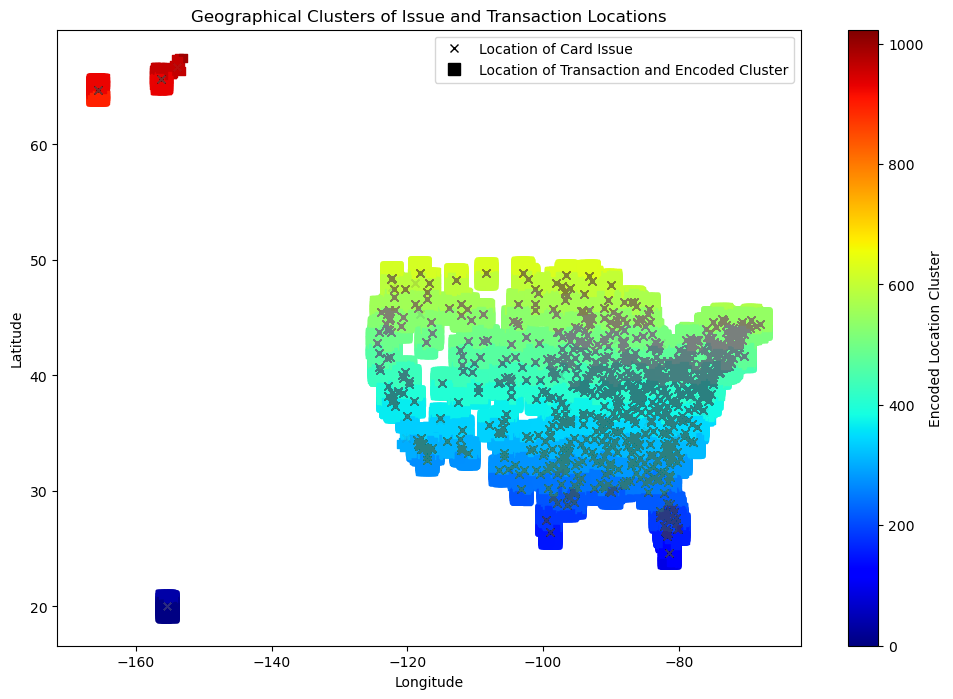

In [30]:
# Create colormap
cmap = cm.get_cmap('jet', 1024)  # 1024 distinct colors
norm = mcolors.Normalize(vmin=0, vmax=1023)

# Plot the locations with color mapping
fig, ax = plt.subplots(figsize=(12, 8))

scatter_transac = ax.scatter(gdf_transac.geometry.x, gdf_transac.geometry.y, 
                             c=gdf_transac['loc_cluster_transac'], cmap=cmap, norm=norm, 
                             marker='s', alpha=1, label='Transaction Location')

scatter_issue = ax.scatter(gdf_issue.geometry.x, gdf_issue.geometry.y, 
                           color='grey',
                           marker='x', alpha=0.01, label='Issue Location')

# Set labels and title
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Geographical Clusters of Issue and Transaction Locations")
legend_elements = [Line2D([0], [0], marker='x', linestyle='None', color='black', label='Location of Card Issue', markerfacecolor='black', markersize=6),
                Line2D([0], [0], marker='s', linestyle='None', color='black', label='Location of Transaction and Encoded Cluster', markerfacecolor='black', markersize=8)]
ax.legend(handles=legend_elements, loc='upper right')

plt.colorbar(scatter_transac, ax=ax, label="Encoded Location Cluster")
plt.show()

In [31]:
# get distance between location of issue and transaction based on latitude and longitude
def calculate_distance(row):
    loc_issue = (row['lat'], row['long'])
    loc_transac = (row['merch_lat'], row['merch_long'])
    return geodesic(loc_issue, loc_transac).kilometers  # Distance in km

df_enc['issue_transac_dist'] = df_enc.apply(calculate_distance, axis=1)

# drop useless and reorder columns
col_to_drop = ['lat', 'long', 'merch_lat', 'merch_long', 'geometry_issue', 'geometry_transac']
df_enc = df_enc.drop(col_to_drop, axis=1)

cols_to_move = ['loc_cluster_issue', 'loc_cluster_transac', 'issue_transac_dist']

moved_cols = [df_enc.pop(col) for col in cols_to_move]

for i, col_name in enumerate(cols_to_move):
    df_enc.insert(25 + i, col_name, moved_cols[i])  # Adjust index dynamically

df_enc

,trans_time,trans_time_grp,category_1,category_2,category_3,category_4a,category_4b,category_4c,category_interaction_1,category_interaction_2,amt,gender,city_1,city_2,city_3,city_4a,city_4b,state_x,state_y,city_pop,job_1,job_2,job_3,job_4,cardholder_age,loc_cluster_issue,loc_cluster_transac,issue_transac_dist,is_fraud
0,0.0,0,1,0,3,0,0,1,0,0,4.97,0,0,2,1,3,0,7,4,3495,2,2,4,2,30,346,346,78.773821,0
1,0.0,0,0,1,3,0,0,0,3,0,107.23,0,1,4,0,0,0,0,0,149,1,2,2,4,40,623,623,30.216618,0
2,0.0,0,0,0,2,0,1,0,0,0,220.11,1,2,0,1,4,1,1,0,4154,1,2,3,3,56,464,496,108.102912,0
3,0.0,0,0,1,2,0,0,0,2,0,45.00,1,3,0,2,0,2,2,0,1939,3,2,4,2,51,560,560,95.685115,0
4,0.0,0,0,0,1,0,0,1,0,0,41.96,1,1,0,0,0,0,7,3,99,0,1,2,0,32,411,411,77.702395,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1296670,12900.0,1,0,0,2,0,1,0,0,0,15.56,1,2,1,2,3,4,1,2,258,2,2,3,4,58,368,369,119.696415,0
1296671,12900.0,1,0,1,0,0,1,0,0,0,51.70,1,2,3,2,0,3,8,8,100,2,1,2,2,40,411,411,75.202184,0
1296672,12900.0,1,0,1,0,0,1,0,0,0,105.93,1,0,4,0,0,1,2,3,899,3,1,3,3,52,274,307,98.987927,0
1296673,12900.0,1,0,1,0,0,1,0,0,0,74.90,1,3,4,1,2,2,3,1,1126,1,2,3,2,39,499,499,84.688356,0


#### Save Encoded Data as CSV

In [32]:
df_enc.to_csv("fraudTrain_encoded.csv", index=False)

#### Find Feature

In [ ]:
plt.figure(figsize = (16,16))
plt.title('Credit Card Transactions features correlation plot (Pearson)')
corr = df_enc.corr()
sns.heatmap(corr,xticklabels=corr.columns,yticklabels=corr.columns,linewidths=.1,cmap="Reds",annot=True)
plt.show()

In [ ]:
warnings.filterwarnings('ignore') # disable Python warning for this cell

var = df_enc.columns.values # get all column names

i = 0
t0 = df_enc.loc[df_enc['is_fraud'] == 0]
t1 = df_enc.loc[df_enc['is_fraud'] == 1]

sns.set_style('whitegrid')
plt.figure()
fig, ax = plt.subplots(5,3,figsize=(16,20)) # subplots of graphs, 4 rows 4 columns

for feature in var: # getting each item of df_enc columns
    i += 1
    plt.subplot(4,4,i)
    sns.kdeplot(t0[feature], bw=0.5,label="is_fraud = 0")
    sns.kdeplot(t1[feature], bw=0.5,label="is_fraud = 1")
    plt.xlabel(feature, fontsize=12)
    locs, labels = plt.xticks()
    plt.tick_params(axis='both', which='major', labelsize=12)
plt.show();

#### Rule Extraction

In [ ]:
df_enc = pd.read_csv(path+"fraudTrain_encoded.csv")

df_enc

##### discretize the encoded df

In [ ]:
# define df and the features columns
df = df_enc.copy()

features = ['trans_time', 'category_0', 'category_1', 'category_2', 'amt', 'gender',
            'city', 'state_x', 'state_y', 'lat', 'long', 'city_pop', 'job',
            'cardholder_age', 'merch_lat', 'merch_long', 
            'is_fraud']

# Discretize 'trans_time' into 6 groups (approx. 4 seasons in 1.3 years)
print("Transaction Time:")
n_grp = 6
discretizer = KBinsDiscretizer(n_bins=n_grp, encode='ordinal', strategy='uniform')
min_ = df_enc['trans_time'].min()
max_ = df_enc['trans_time'].max()
step = (min_+max_)/n_grp
base = min_+step
print(f"group 0: {min_}-{base}")
for n in range(1, n_grp):
    print(f"group {n}: {base}-{base+step}")
    base = base+step    
df[['trans_time']] = discretizer.fit_transform(df[['trans_time']])
print(df['trans_time'].value_counts())

# Discretize 'amt' into 20 groups
print("\nAmount:")
n_grp = 20
discretizer = KBinsDiscretizer(n_bins=n_grp, encode='ordinal', strategy='quantile')   
df[['amt']] = discretizer.fit_transform(df[['amt']])
bin_edges = discretizer.bin_edges_[0]
bin_ranges = []
for i in range(len(bin_edges) - 1):
    bin_ranges.append((bin_edges[i], bin_edges[i+1]))
for i, (min_val, max_val) in enumerate(bin_ranges): # print out values of each group
    print(f"group {i}: min = {min_val}, max = {max_val}")
print(df['amt'].value_counts())

# Discretize 'city' into 50 groups
print("\nCity:")
n_grp = 50
discretizer = KBinsDiscretizer(n_bins=n_grp, encode='ordinal', strategy='uniform')
min_ = df_enc['city'].min()
max_ = df_enc['city'].max()
step = (min_+max_)/n_grp
base = min_+step
print(f"group 0: {min_}-{base}")
for n in range(1, n_grp):
    print(f"group {n}: {base}-{base+step}")
    base = base+step 
df[['city']] = discretizer.fit_transform(df[['city']])
print(df['city'].value_counts())

# Discretize 'lat' into 4 groups
print("\nLat:")
n_grp = 4
discretizer = KBinsDiscretizer(n_bins=n_grp, encode='ordinal', strategy='quantile')
df[['lat']] = discretizer.fit_transform(df[['lat']])
bin_edges = discretizer.bin_edges_[0]
bin_ranges = []
for i in range(len(bin_edges) - 1):
    bin_ranges.append((bin_edges[i], bin_edges[i+1]))
for i, (min_val, max_val) in enumerate(bin_ranges): # print out values of each group
    print(f"group {i}: min = {min_val}, max = {max_val}")
print(df['lat'].value_counts())

# Discretize 'long' into 10 groups
print("\nLong:")
n_grp = 10
discretizer = KBinsDiscretizer(n_bins=n_grp, encode='ordinal', strategy='quantile')
df[['long']] = discretizer.fit_transform(df[['long']])
bin_edges = discretizer.bin_edges_[0]
bin_ranges = []
for i in range(len(bin_edges) - 1):
    bin_ranges.append((bin_edges[i], bin_edges[i+1]))
for i, (min_val, max_val) in enumerate(bin_ranges): # print out values of each group
    print(f"group {i}: min = {min_val}, max = {max_val}")
print(df['long'].value_counts())

# Discretize 'city_pop' into 20 groups
print("\nCity Population:")
n_grp = 20
discretizer = KBinsDiscretizer(n_bins=n_grp, encode='ordinal', strategy='quantile') 
df[['city_pop']] = discretizer.fit_transform(df[['city_pop']])
bin_edges = discretizer.bin_edges_[0]
bin_ranges = []
for i in range(len(bin_edges) - 1):
    bin_ranges.append((bin_edges[i], bin_edges[i+1]))
for i, (min_val, max_val) in enumerate(bin_ranges): # print out values of each group
    print(f"group {i}: min = {min_val}, max = {max_val}")
print(df['city_pop'].value_counts())

# Discretize 'job' into 20 groups
print("\nJob:")
n_grp = 20
discretizer = KBinsDiscretizer(n_bins=n_grp, encode='ordinal', strategy='uniform')
min_ = df_enc['job'].min()
max_ = df_enc['job'].max()
step = (min_+max_)/n_grp
base = min_+step
print(f"group 0: {min_}-{base}")
for n in range(1, n_grp):
    print(f"group {n}: {base}-{base+step}")
    base = base+step 
df[['job']] = discretizer.fit_transform(df[['job']])
print(df['job'].value_counts())

# Discretize 'cardholder_age' into 18 groups
print("\nAge:")
n_grp = 18
discretizer = KBinsDiscretizer(n_bins=n_grp, encode='ordinal', strategy='uniform')
min_ = df_enc['cardholder_age'].min()
max_ = df_enc['cardholder_age'].max()
step = (min_+max_)/n_grp
base = min_+step
print(f"group 0: {min_}-{base}")
for n in range(1, n_grp):
    print(f"group {n}: {base}-{base+step}")
    base = base+step 
df[['cardholder_age']] = discretizer.fit_transform(df[['cardholder_age']])
print(df['cardholder_age'].value_counts())

# Discretize 'merch_lat' into 4 groups
print("\nMerch_lat:")
n_grp = 4
discretizer = KBinsDiscretizer(n_bins=n_grp, encode='ordinal', strategy='quantile')
df[['merch_lat']] = discretizer.fit_transform(df[['merch_lat']])
bin_edges = discretizer.bin_edges_[0]
bin_ranges = []
for i in range(len(bin_edges) - 1):
    bin_ranges.append((bin_edges[i], bin_edges[i+1]))
for i, (min_val, max_val) in enumerate(bin_ranges): # print out values of each group
    print(f"group {i}: min = {min_val}, max = {max_val}")
print(df['merch_lat'].value_counts())

# Discretize 'merch_long' into 10 groups
print("\nMerch_long:")
n_grp = 10
discretizer = KBinsDiscretizer(n_bins=n_grp, encode='ordinal', strategy='quantile')
df[['merch_long']] = discretizer.fit_transform(df[['merch_long']])
bin_edges = discretizer.bin_edges_[0]
bin_ranges = []
for i in range(len(bin_edges) - 1):
    bin_ranges.append((bin_edges[i], bin_edges[i+1]))
for i, (min_val, max_val) in enumerate(bin_ranges): # print out values of each group
    print(f"group {i}: min = {min_val}, max = {max_val}")
print(df['merch_long'].value_counts())


df

##### train-test split the discretized df and define function to transform training entries into transactions

In [ ]:
# Split the train and test df

# train_df, test_df = train_test_split(df, test_size=TEST_SIZE, # TEST_SIZE, RANDOM_STATE was defined earlier in 1st cell (0.2 and 2018 respec.)
#                                      random_state=RANDOM_STATE, shuffle=True) # shuffle=True so train data get first 80% with order and shuffle
# train_df, valid_df = train_test_split(train_df, test_size=VALID_SIZE,
#                                       random_state=RANDOM_STATE, shuffle=True)

In [ ]:
# train_df['is_fraud'].value_counts()

In [ ]:
def transform_to_transactions(data):
    trans = []
    for _, row in data.iterrows():
        trans.append([f'trans_time = group {int(row["trans_time"])}', 
                      f'category_0 = {int(row["category_0"])}', 
                      f'category_1 = {int(row["category_1"])}', 
                      f'category_2 = {int(row["category_2"])}', 
                      f'amt = group {int(row["amt"])}', 
                      f'gender = group {int(row["gender"])}', 
                      f'city = group {int(row["city"])}', 
                      f'state_x = {int(row["state_x"])}', 
                      f'state_y = {int(row["state_y"])}', 
                      f'lat = group {int(row["lat"])}', 
                      f'long = group {int(row["long"])}', 
                      f'city_pop = group {int(row["city_pop"])}', 
                      f'job = group {int(row["job"])}', 
                      f'cardholder_age = group {int(row["cardholder_age"])}', 
                      f'merch_lat = group {int(row["merch_lat"])}', 
                      f'merch_long = group {int(row["merch_long"])}',
                      f'is_fraud = {int(row["is_fraud"])}'])
        
    return trans

##### obtain the rules of whole dataset

In [ ]:
transactions = transform_to_transactions(df) # transform the data into transactions

transactions[:5] # show transformed transactions

In [ ]:
# Encode transactions
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_apriori = pd.DataFrame(te_ary, columns=te.columns_)

# Apply Apriori algorithm
frequent_itemsets = apriori(df_apriori, min_support=0.5, use_colnames=True)
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1)

print(rules.shape)
rules.sort_values(by=['lift', 'confidence'], ascending=False)[:10]

In [ ]:
my_rules = rules.copy()

my_rules['consequents'] = my_rules['consequents'].apply(lambda x: list(x)[0]).astype("unicode")
my_rules = my_rules.loc[my_rules['consequents']=="is_fraud = 0"]

my_rules.sort_values(by=['lift', 'confidence'], ascending=False)[:10]

##### obtain rules of balanced non fraud and fraud data (use SMOTE)

In [ ]:
# nonFraud_index = list(train_df.loc[train_df['is_fraud'] == 0].index) # obtain index that has target is_fraud==0
# Fraud_index = list(train_df.loc[train_df['is_fraud'] == 1].index) # obtain index that has target is_fraud==1

# random.seed(RANDOM_STATE)
# random_nonFraud = np.array(random.sample(nonFraud_index, 4000)) # obtain 4000 indeces from the non Fraud indeces
# random_Fraud = np.array(random.sample(Fraud_index, 4000)) # obtain 4000 indeces from the Fraud indeces
# random_nonFraud_Fraud = np.concatenate((random_nonFraud, random_Fraud)) # now we have indeces of 50% of non fraud and 50% of fraud entries

In [ ]:
target = 'is_fraud'
predictors = ['trans_time', 'category_0', 'category_1', 'category_2', 'amt', 
              'gender', 'city', 'state_x', 'state_y', 'lat', 'long', 'city_pop', 
              'job','cardholder_age', 'merch_lat', 'merch_long']


rus = RandomUnderSampler(sampling_strategy=0.02, random_state=RANDOM_STATE) # under sample class 0 to about 1/4 of its size
X, y = rus.fit_resample(df[predictors], df[target])

sm = SMOTE(sampling_strategy=0.1, random_state=RANDOM_STATE) # over sample
X, y = sm.fit_resample(X, y)


df_nonFraud_Fraud = pd.DataFrame(X, columns=predictors)
df_nonFraud_Fraud[target] = y

In [ ]:
transactions = transform_to_transactions(df_nonFraud_Fraud) # transform the data into transactions
transactions[:5] # show transformed transactions

In [ ]:
# Encode transactions
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_apriori = pd.DataFrame(te_ary, columns=te.columns_)

# Apply Apriori algorithm
frequent_itemsets = apriori(df_apriori, min_support=0.5, use_colnames=True)
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1)

print(rules.shape)
rules.sort_values(by=['lift', 'confidence'], ascending=False)[:10]

In [ ]:
my_rules = rules.copy()

my_rules['consequents'] = my_rules['consequents'].apply(lambda x: list(x)[0]).astype("unicode")
print(my_rules['consequents'].value_counts())

In [ ]:
my_rules = my_rules.loc[my_rules['consequents']=="is_fraud = 0"]
my_rules.sort_values(by=['lift', 'confidence'], ascending=False)[:10]

In [ ]:
my_rules = my_rules.loc[my_rules['consequents']=="is_fraud = 1"]
my_rules.sort_values(by=['lift', 'confidence'], ascending=False)[:10]

##### obtain rules for non fraud only

In [ ]:
df_nonFraud = df.loc[df['is_fraud']==0] # get only fraud entries

transactions = transform_to_transactions(df_nonFraud) # transform the data into transactions

transactions[:5] # show transformed transactions

In [ ]:
# Encode transactions
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_apriori = pd.DataFrame(te_ary, columns=te.columns_)

# Apply Apriori algorithm
frequent_itemsets = apriori(df_apriori, min_support=0.5, use_colnames=True)
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1)

print(rules.shape)
rules.sort_values(by=['lift', 'confidence'], ascending=False)[:10]

In [ ]:
my_rules = rules.copy()

my_rules['consequents'] = my_rules['consequents'].apply(lambda x: list(x)[0]).astype("unicode")
print(my_rules['consequents'].value_counts())

In [ ]:
my_rules = my_rules.loc[my_rules['consequents']=="is_fraud = 0"]
my_rules.sort_values(by=['lift', 'confidence'], ascending=False)

##### obtain rules for fraud only

In [ ]:
df_Fraud = df.loc[df['is_fraud']==1] # get only fraud entries

transactions = transform_to_transactions(df_Fraud) # transform the data into transactions

transactions[:5] # show transformed transactions

In [ ]:
# Encode transactions
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_apriori = pd.DataFrame(te_ary, columns=te.columns_)

# Apply Apriori algorithm
frequent_itemsets = apriori(df_apriori, min_support=0.5, use_colnames=True)
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1)

print(rules.shape)
rules.sort_values(by=['lift', 'confidence'], ascending=False)[:10]

In [ ]:
my_rules = rules.copy()

my_rules['consequents'] = my_rules['consequents'].apply(lambda x: list(x)[0]).astype("unicode")
print(my_rules['consequents'].value_counts())

In [ ]:
my_rules = my_rules.loc[my_rules['consequents']=="is_fraud = 1"]
my_rules.sort_values(by=['lift', 'confidence'], ascending=False)

In [ ]:
df['amt'].value_counts()

# df_Fraud.shape